# load things for science :)

In [1]:
import uproot
import itertools
import numpy as np
import pandas as pd
from pathlib import Path
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from scipy.optimize import curve_fit
from matplotlib.ticker import FormatStrFormatter
from mpl_toolkits.axes_grid1 import make_axes_locatable

# load root file (carefully)

In [2]:
branches = [
    'event',
    'w',
    'q2',
    'weight',
    'mm2_mPim',
    'mm2_mPip',
    'mm2_mProt',
    'mm2_excl',
    'pim_mom_miss',
    'pim_mom_meas',
    'pip_mom_miss',
    'pip_mom_meas',
    'prot_mom_miss',
    'prot_mom_meas',
    'excl_mom',
    'pim_theta_miss',
    'pim_theta_meas',
    'pip_theta_miss',
    'pip_theta_meas',
    'prot_theta_miss',
    'prot_theta_meas',
    'pim_theta_angle_btwn_P',
    'pip_theta_angle_btwn_P',
    'prot_theta_angle_btwn_P'
]

In [3]:
gen_branches = [
    'run',
    'event_mc',
    'w_mc',
    'q2_mc',
    'weight_mc',
    'pid_prot_mc',
    'pid_pip_mc',
    'pid_pim_mc'
]

In [4]:
# filename = ("/Users/aosmond/nuclearPhys/csv/finished_csv/10_2GeV/sp19inb_exp/10_2exp_excl_sp19inb_pass2_jlab_06_16_2026.csv")

# df = pd.read_csv(filename)

# print(f"Number of entries: {len(df):,}")

In [5]:
# import pandas as pd

# filename = "/Users/aosmond/nuclearPhys/csv/finished_csv/10_6GeV/threepion/10_6rec_excl_3pion_withBG_jlab_07_22_2025.csv"

# df = pd.read_csv(filename)
# print(f"Number of entries (rows): {len(df):,}")

In [6]:
folder_name = "experiment"      # simulationTEST, experimentTEST, experimentTESTw3pion
data_name = "fall18_inb"          # spring19_inb_50nA, spring19_inb
topology_name = "EXCL"
hist_base_path = Path(f'/Users/aosmond/nuclearPhys/notebooks/notebook_hists_fromRoot/{folder_name}/{data_name}/{topology_name}_topology')

# filename = ("/Users/aosmond/nuclearPhys/root/finished_root/sp19inb/simulation/10_2rec_excl_sp19inb_50nA_jlab_07_17_2026_32threads.root")
filename = ("/Users/aosmond/nuclearPhys/root/finished_root/fa18inb/experiment/10_6exp_excl_fa18inb_jlab_11_06_2026_thread0.root")
threepion_filename = ("/Users/aosmond/nuclearPhys/root/finished_root/fa18inb/simulation/10_6rec_excl_3pion_wBG_fa18inb_jlab_11_06_2026_thread0.root")

file = uproot.open(filename)
full_tree = file["events"]

# Keep this as a TTree-like uproot object.
# Do NOT turn the entire ROOT file into arrays.
tree = full_tree

threepion_file = uproot.open(threepion_filename)
threepion_full_tree = threepion_file["events"]

threepion_toggle = True     # set True/False for including/excluding threepion in the following code

print("ROOT entries in file:", full_tree.num_entries)

STEP_SIZE = "500 MB"

TEST_MODE = False

if TEST_MODE:
    entry_stop = 10_000_000
else:
    entry_stop = full_tree.num_entries

# threepion_entry_stop = threepion_full_tree.num_entries
threepion_entry_stop = min(140_000, threepion_full_tree.num_entries)

print("Events to process:", entry_stop)
print("Three-pion ROOT entries:", threepion_full_tree.num_entries)

ROOT entries in file: 4084286
Events to process: 4084286
Three-pion ROOT entries: 7728689


In [7]:
first_events = tree.arrays(branches, entry_start=0, entry_stop=5, library="pd")
print(first_events)

   event         w        q2  weight  mm2_mPim  mm2_mPip  mm2_mProt  mm2_excl  \
0      0  2.202311  2.430970     1.0  0.631194  0.664800   1.881174  0.086615   
1      0  1.530922  3.238755     1.0 -0.009482 -0.009716   0.846677 -0.003581   
2      0  2.394385  2.517343     1.0  0.589831  0.384090   2.063968  0.065455   
3      0  2.453374  3.894055     1.0  0.535465  0.600490   3.405813  0.244929   
4      0  1.949069  2.581187     1.0 -0.047009  0.017311   0.789917 -0.000287   

   pim_mom_miss  pim_mom_meas  ...  excl_mom  pim_theta_miss  pim_theta_meas  \
0      0.850073      0.503881  ...  0.569088       13.301034       45.802803   
1      1.081962      1.153429  ...  0.103357       39.284634       35.464672   
2      1.318203      0.335076  ...  1.134131       21.964344       72.252037   
3      3.037809      1.307224  ...  1.741073       23.587250       18.522545   
4      0.345307      0.336913  ...  0.097412       85.757828       71.345024   

   pip_theta_miss  pip_theta_mea

In [8]:
last_events = tree.arrays(branches, entry_start=tree.num_entries-5, entry_stop=tree.num_entries, library="pd")
print(last_events)

         event         w        q2  weight  mm2_mPim  mm2_mPip  mm2_mProt  \
4084281      0  1.672946  3.918082     1.0  0.192277  0.133304   1.480264   
4084282      0  2.344197  2.680543     1.0  1.104114  0.725244   2.361992   
4084283      0  2.478008  4.750628     1.0  0.880395  0.770912   3.099344   
4084284      0  2.417095  2.434819     1.0  0.787363  0.244084   1.376399   
4084285      0  2.349871  4.749261     1.0  1.077721  0.839668   3.189437   

         mm2_excl  pim_mom_miss  pim_mom_meas  ...  excl_mom  pim_theta_miss  \
4084281 -0.026179      1.667644      0.742801  ...  0.981952       26.378960   
4084282  0.102659      2.395621      0.872162  ...  1.702793       11.516348   
4084283  0.329125      3.116232      0.722784  ...  2.452074       20.196344   
4084284 -0.014008      1.497457      1.574206  ...  0.199205       12.173213   
4084285  0.342857      1.697515      1.058098  ...  0.712884       17.466993   

         pim_theta_meas  pip_theta_miss  pip_theta_meas 

In [9]:
print(threepion_full_tree.keys())

['event', 'w', 'q2', 'weight', 'pid_prot_rec', 'pid_pip_rec', 'pid_pim_rec', 'pid_prot_mc', 'pid_pip_mc', 'pid_pim_mc', 'mm2_mPim', 'mm2_mPip', 'mm2_mProt', 'mm2_excl', 'pim_mom_miss', 'pim_mom_meas', 'pip_mom_miss', 'pip_mom_meas', 'prot_mom_miss', 'prot_mom_meas', 'excl_mom', 'pim_theta_miss', 'pim_theta_meas', 'pip_theta_miss', 'pip_theta_meas', 'prot_theta_miss', 'prot_theta_meas', 'pim_theta_angle_btwn_P', 'pip_theta_angle_btwn_P', 'prot_theta_angle_btwn_P']


In [10]:
threepion_first_events = threepion_full_tree.arrays(branches, entry_start=0, entry_stop=5, library="pd")
print(threepion_first_events)

      event         w        q2    weight  mm2_mPim  mm2_mPip  mm2_mProt  \
0  16843009  2.416420  6.971068  0.017364  0.557429  0.498718   2.873156   
1  16843009  2.447400  7.596459  0.013585  0.376830  0.862388   2.760374   
2  16843009  2.340384  2.429214  0.001938  0.323536  0.308472   1.295855   
3  16843009  2.410653  4.253249  0.012065  0.933953  0.598639   1.839893   
4  16843009  2.369859  5.119995  0.008503  0.262172  0.307436   1.321206   

   mm2_excl  pim_mom_miss  pim_mom_meas  ...  excl_mom  pim_theta_miss  \
0  0.012600      2.790691      1.535367  ...  1.342456        8.265382   
1  0.052918      1.239121      1.003634  ...  0.289221       21.524324   
2  0.022535      0.638015      0.507686  ...  0.291889       40.708622   
3  0.077867      2.169046      0.679676  ...  1.657413       18.920763   
4  0.034422      1.910426      1.593286  ...  0.329870       30.856274   

   pim_theta_meas  pip_theta_miss  pip_theta_meas  prot_theta_miss  \
0       16.013197        3.3

In [11]:
threepion_last_events = threepion_full_tree.arrays(branches, entry_start=threepion_full_tree.num_entries-5, entry_stop=threepion_full_tree.num_entries, library="pd")
print(threepion_last_events)

            event         w        q2    weight  mm2_mPim  mm2_mPip  \
7728684  16843009  2.240058  6.424000  0.009491  0.440715  0.392563   
7728685  16843009  2.390917  8.146794  0.025336  0.603484  1.098546   
7728686  16843009  2.376688  2.248573  0.015440  0.343452  0.562932   
7728687  16843009  2.087663  5.002361  0.002950  0.233722  0.363215   
7728688  16843009  2.222867  7.722619  0.013793  0.117254  0.178563   

         mm2_mProt  mm2_excl  pim_mom_miss  pim_mom_meas  ...  excl_mom  \
7728684   1.684342  0.006923      1.681780      1.637556  ...  0.141990   
7728685   1.643645  0.007295      2.344877      1.499805  ...  0.960133   
7728686   1.597878  0.055302      1.956063      1.327078  ...  0.667348   
7728687   1.371092  0.036016      2.029069      1.296564  ...  0.758430   
7728688   1.861327  0.018762      2.029696      0.807418  ...  1.231391   

         pim_theta_miss  pim_theta_meas  pip_theta_miss  pip_theta_meas  \
7728684       24.153229       26.476805       2

# W-Q2 range

### set up bins

In [12]:
w_min, w_max = 1.35, 2.50
q2_min, q2_max = 1.6, 12.0

n_w_bins = 300
n_q2_bins = 300

fine_bin_x = np.linspace(w_min, w_max, n_w_bins + 1)
fine_bin_y = np.linspace(q2_min, q2_max, n_q2_bins + 1)

# Accumulator for weighted W-Q² histogram
wq2_hist = np.zeros((n_w_bins, n_q2_bins), dtype=np.float64)

# Number of events processed
wq2_events = 0

# Read ROOT file in chunks
with tqdm(unit="events", desc="Building W-Q² histogram") as pbar:

    for chunk in full_tree.iterate(branches, library="pd"):

        # Same mask as your original W-Q² histogram
        mask = (
            chunk["w"].notna()
            & chunk["q2"].notna()
            & (chunk["w"] >= w_min)
            & (chunk["w"] <= w_max)
            & (chunk["q2"] >= q2_min)
            & (chunk["q2"] <= q2_max)
        )

        w_vals = chunk.loc[mask, "w"].to_numpy()
        q2_vals = chunk.loc[mask, "q2"].to_numpy()
        weights = chunk.loc[mask, "weight"].to_numpy()

        # Accumulate weighted 2D histogram
        h_chunk, _, _ = np.histogram2d(w_vals, q2_vals, bins=[fine_bin_x, fine_bin_y], weights=weights)

        wq2_hist += h_chunk
        wq2_events += len(w_vals)
        pbar.update(len(chunk))

print()
print("Events inside W-Q² plotting range:", wq2_events)

Building W-Q² histogram: 0events [00:00, ?events/s]


Events inside W-Q² plotting range: 4073182


### plot W-Q2


========== W vs Q² EVENT COUNTS ==========
Solid pink box:  3,450,244 events
Dashed pink box: 1,171,745 events


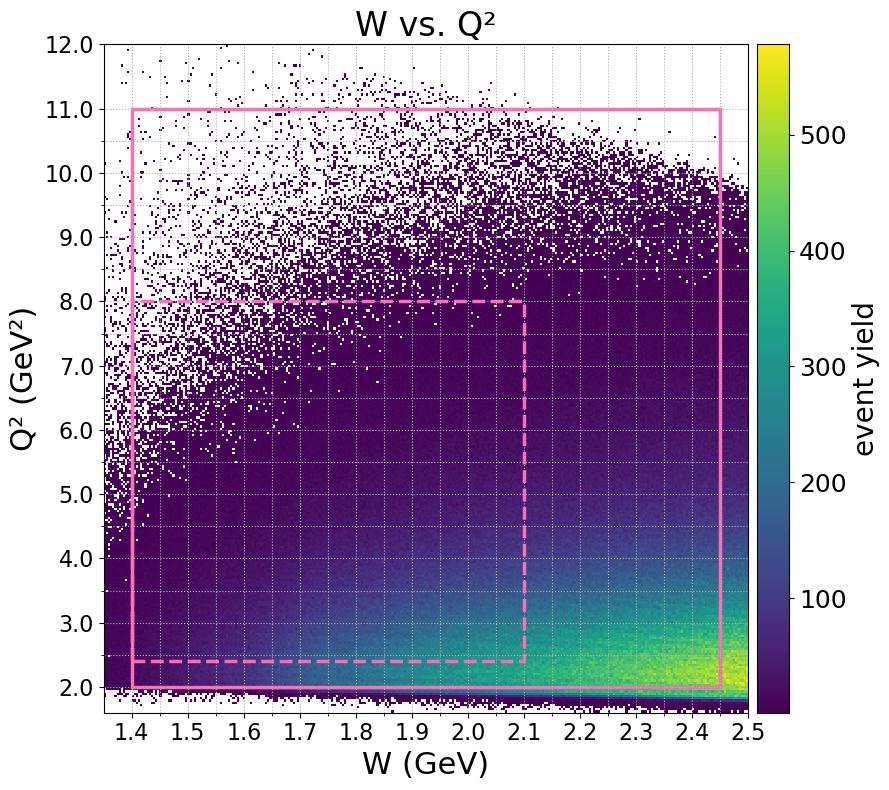

In [13]:
# Plot W vs Q² histogram
fig, ax = plt.subplots(figsize=(9, 8))

# Plot the accumulated histogram
hist_masked = np.ma.masked_where(wq2_hist.T <= 0, wq2_hist.T)

h = ax.pcolormesh(fine_bin_x, fine_bin_y, hist_masked, cmap="viridis", shading="auto")

# Match the original title and labels
ax.set_title("W vs. Q²", fontsize=24)
ax.set_xlabel("W (GeV)", fontsize=22)
ax.set_ylabel("Q² (GeV²)", fontsize=22)

divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="5%", pad=0.09)
cb = plt.colorbar(h, cax=cax)
cb.set_label("event yield", fontsize=20)
cb.ax.tick_params(labelsize=18)

ax.grid(which="both", linestyle=":")

ax.tick_params(axis="both", which="major", labelsize=16)
ax.set_xticks(np.append(np.arange(1.4, 2.5, 0.1), 2.5))
ax.set_xticks(np.arange(1.4, 2.51, 0.05), minor=True)
ax.set_yticks(np.arange(2.0, 12.1, 1))
ax.set_yticks(np.arange(2.0, 11.1, 0.5), minor=True)
ax.yaxis.set_major_formatter(FormatStrFormatter("%.1f"))

# ------------------------------------------------------------
# Main analyzed region
# ------------------------------------------------------------

w_min_analyzed = 1.4
w_max_analyzed = 2.45

q2_min_analyzed = 2.0
q2_max_analyzed = 11.0

rect = patches.Rectangle(
    (w_min_analyzed, q2_min_analyzed),
    w_max_analyzed - w_min_analyzed,
    q2_max_analyzed - q2_min_analyzed,
    linewidth=2.5,
    edgecolor="hotpink",
    alpha=1.0,
    facecolor="none"
)

# Krishna analyzed region
w_min_analyzed_krishna = 1.4
w_max_analyzed_krishna = 2.10

q2_min_analyzed_krishna = 2.4
q2_max_analyzed_krishna = 8.0

rect_krishna = patches.Rectangle(
    (w_min_analyzed_krishna, q2_min_analyzed_krishna),
    w_max_analyzed_krishna - w_min_analyzed_krishna,
    q2_max_analyzed_krishna - q2_min_analyzed_krishna,
    linewidth=2.5,
    edgecolor="hotpink",
    alpha=1.0,
    linestyle="--",
    facecolor="none"
)

# ------------------------------------------------------------
# Count raw events inside the pink boxes
# ------------------------------------------------------------

# Bin centers
w_centers = (fine_bin_x[:-1] + fine_bin_x[1:]) / 2
q2_centers = (fine_bin_y[:-1] + fine_bin_y[1:]) / 2

# Solid pink box
solid_mask = (
    (w_centers >= w_min_analyzed)
    & (w_centers < w_max_analyzed)
)

solid_q2_mask = (
    (q2_centers >= q2_min_analyzed)
    & (q2_centers < q2_max_analyzed)
)

# Dashed pink box
dashed_mask = (
    (w_centers >= w_min_analyzed_krishna)
    & (w_centers < w_max_analyzed_krishna)
)

dashed_q2_mask = (
    (q2_centers >= q2_min_analyzed_krishna)
    & (q2_centers < q2_max_analyzed_krishna)
)

# Count events in each region
solid_events = wq2_hist[np.ix_(solid_mask, solid_q2_mask)].sum()
dashed_events = wq2_hist[np.ix_(dashed_mask, dashed_q2_mask)].sum()

print("\n========== W vs Q² EVENT COUNTS ==========")
print(f"Solid pink box:  {solid_events:,.0f} events")
print(f"Dashed pink box: {dashed_events:,.0f} events")
print("==========================================")

ax.add_patch(rect)
ax.add_patch(rect_krishna)

plt.tight_layout()
plt.show()

# w-q2 binned cuts

## set w-q2 values for analysis

In [14]:
# w and q2 ranges
w_bins = np.append(np.arange(1.4, 2.5, 0.05), 2.5)
q2_bins = [2.0,2.4,3.0,3.5,4.2,5.0,6.0,7.0,8.0,9.0,10.0,11.0] #,13.0]
# q2_bins = np.arange(2.0, 12.1, 0.5)

bins_value = 100

print("W bins:", len(w_bins) - 1)
print("Q² bins:", len(q2_bins) - 1)
print("Total W/Q² analysis bins:", (len(w_bins) - 1) * (len(q2_bins) - 1))

W bins: 22
Q² bins: 11
Total W/Q² analysis bins: 242


## mm2 cuts

### create sigma cuts

In [15]:
# MM² TOPOLOGY DEFINITIONS
topologies_mm2 = {
    "excl":  {"range": (-0.03, 0.03), "fit_window": (-0.02, 0.02)},
    "mProt": {"range": (-0.1, 2.5),  "fit_window": (0.4, 1.25)},
    "mPip":  {"range": (-0.2, 0.2),  "fit_window": (-0.2, 0.2)},
    "mPim":  {"range": (-0.2, 0.25), "fit_window": (-0.2, 0.25)}
}

# Sigma windows
sigma_factors = [
    (-1.25, 1.25),
    (-1.5, 2.0),
    (-4.0, 4.5)
]

# Gaussian function
def gaussian(x, amp, mean, sigma):
    return amp * np.exp(-0.5 * ((x - mean) / sigma) ** 2)

binned_hist_path = Path("MM2_binned_wq2/mm2_cuts")

# FUNCTION TO BUILD MM² HISTOGRAMS
def build_mm2_histograms(input_tree, max_entries, description):

    # Create empty histograms
    histograms = {}

    for w_bin in range(len(w_bins) - 1):
        for q2_bin in range(len(q2_bins) - 1):
            for topo, settings in topologies_mm2.items():

                counts, edges = np.histogram([], bins=bins_value, range=settings["range"])

                histograms[(w_bin, q2_bin, topo)] = {
                    "counts": counts.astype(np.float64),
                    "edges": edges
                }

    total_events = 0

    # Read the ROOT file in chunks
    with tqdm(total=max_entries, unit="events", desc=description) as pbar:

        for chunk in input_tree.iterate(branches, library="pd", step_size=STEP_SIZE, entry_start=0, entry_stop=max_entries):

            w_values = chunk["w"].to_numpy()
            q2_values = chunk["q2"].to_numpy()
            chunk_weights = chunk["weight"].to_numpy()

            valid_wq2 = (np.isfinite(w_values) & np.isfinite(q2_values))
            w_bin_indices = (np.searchsorted(w_bins, w_values, side="right") - 1)
            q2_bin_indices = (np.searchsorted(q2_bins, q2_values, side="right") - 1)
            valid_wq2 &= ((w_bin_indices >= 0) & (w_bin_indices < len(w_bins) - 1) & (q2_bin_indices >= 0) & (q2_bin_indices < len(q2_bins) - 1))

            if not np.any(valid_wq2):
                pbar.update(len(chunk))
                continue

            valid_indices = np.where(valid_wq2)[0]
            total_events += len(valid_indices)

            chunk_w_bins = w_bin_indices[valid_wq2]
            chunk_q2_bins = q2_bin_indices[valid_wq2]

            # Process each W/Q² bin represented in this chunk
            for w_bin in np.unique(chunk_w_bins):

                w_mask = chunk_w_bins == w_bin

                for q2_bin in np.unique(chunk_q2_bins[w_mask]):

                    local_mask = (w_mask & (chunk_q2_bins == q2_bin))
                    original_indices = valid_indices[local_mask]

                    event_weights = chunk_weights[original_indices]

                    # Process each MM² topology
                    for topo in topologies_mm2:
                        column = f"mm2_{topo}"
                        values = (chunk.iloc[original_indices][column].to_numpy())
                        values = values[np.isfinite(values)]

                        # Keep only finite MM² values and matching weights
                        finite_mask = np.isfinite(values)

                        values = values[finite_mask]
                        finite_weights = event_weights[finite_mask]

                        if len(values) == 0:
                            continue

                        counts, _ = np.histogram(values, bins=histograms[(w_bin, q2_bin, topo)]["edges"], weights=event_weights)
                        histograms[(w_bin, q2_bin, topo)]["counts"] += counts

            pbar.update(len(chunk))

    return histograms, total_events

mm2_histograms, total_mm2_events = build_mm2_histograms(input_tree=full_tree, max_entries=entry_stop, description="Building experimental MM² histograms")

print()
print("Experimental events inside MM² W/Q² analysis region:", total_mm2_events)

Building experimental MM² histograms:   0%|          | 0/4084286 [00:00<?, ?events/s]


Experimental events inside MM² W/Q² analysis region: 3817225


### plot

In [16]:
# FIT MM² HISTOGRAMS AND PLOT MM² CUT WINDOWS
binned_hist_path = Path("MM2_binned_wq2/mm2_cuts")

def bin_label(bin_idx, bin_edges):

    if bin_idx < len(bin_edges) - 1:
        return (f"[{bin_edges[bin_idx]:.2f}, {bin_edges[bin_idx + 1]:.2f})")
    return "[out of range)"

def safe_str(label):
    return label.strip("[]()").replace(",", "_").replace(" ", "")

# SIGMA COLORS
USE_MANUAL_COLORS = True

if USE_MANUAL_COLORS:
    sigma_colors = [
        "limegreen",
        "magenta",
        "darkviolet",
    ]
else:
    cmap = plt.cm.rainbow_r
    sigma_colors = cmap(np.linspace(0, 1, len(sigma_factors)))


# FIT EACH EXPERIMENTAL HISTOGRAM AND PLOT
total_histograms = (
    (len(w_bins) - 1)
    * (len(q2_bins) - 1)
    * len(topologies_mm2)
)

mm2_fit_parameters = {}

with tqdm(total=total_histograms, unit="hist", desc="Fitting and saving MM² histograms") as pbar:

    for w_bin in range(len(w_bins) - 1):
        for q2_bin in range(len(q2_bins) - 1):

            # Labels used in the original filenames
            w_label = bin_label(w_bin, w_bins)
            q2_label = bin_label(q2_bin, q2_bins)

            for topo, settings in topologies_mm2.items():

                key = (w_bin, q2_bin, topo)

                # EXPERIMENTAL HISTOGRAM
                counts = mm2_histograms[key]["counts"]
                edges = mm2_histograms[key]["edges"]
                bin_centers = (edges[:-1] + edges[1:]) / 2.0

                x_min, x_max = settings["range"]
                n_events = counts.sum()

                fit_window = settings["fit_window"]
                fit_window_left, fit_window_right = fit_window
                fit_mask = ((bin_centers >= fit_window_left) & (bin_centers <= fit_window_right))

                amp_fit = None
                mean_fit = None
                sigma_fit = None

                try:
                    if not np.any(fit_mask):
                        raise ValueError("No histogram bins in fit window.")

                    local_values = counts[fit_mask]
                    local_centers = bin_centers[fit_mask]

                    if local_values.sum() == 0:
                        raise ValueError("No counts in fit window.")

                    local_peak_idx = np.argmax(local_values)
                    global_peak_idx = np.where(fit_mask)[0][local_peak_idx]
                    peak_x = bin_centers[global_peak_idx]

                    x_fit = local_centers
                    y_fit = local_values

                    if len(x_fit) < 3:
                        raise ValueError("Insufficient points for Gaussian fit.")

                    amp_guess = float(y_fit.max())
                    mean_guess = float(peak_x)
                    sigma_guess = max(1e-6, 0.25 * (fit_window_right - fit_window_left))

                    popt, pcov = curve_fit(gaussian, x_fit, y_fit, p0=[amp_guess, mean_guess, sigma_guess], maxfev=20000)

                    amp_fit = popt[0]
                    mean_fit = popt[1]
                    sigma_fit = abs(popt[2])

                except Exception as e:
                    print(f"Skipping bad fit -> {topo}, W-bin {w_bin}, Q2-bin {q2_bin}: {e}")

                # Save experimental fit parameters
                mm2_fit_parameters[key] = {
                    "mean": mean_fit,
                    "sigma": sigma_fit,
                    "amplitude": amp_fit
                }

                # PLOT
                plt.figure(figsize=(11, 7))
                plt.step(bin_centers, counts, where="mid", color="black", linewidth=0.8, alpha=0.8, label=f"(N={n_events:,})")

                # Gaussian fit to experimental histogram
                if (amp_fit is not None
                    and sigma_fit is not None
                    and mean_fit is not None
                ):

                    x_dense = np.linspace(max(x_min, fit_window_left), min(x_max, fit_window_right), 1000)
                    y_dense = gaussian(x_dense, amp_fit, mean_fit, sigma_fit)

                    plt.plot(x_dense, y_dense, color="blue", alpha=0.6, linewidth=1.0, label="gaussian fit")
                    plt.axvline(mean_fit, color="blue", linestyle="--", alpha=0.6, linewidth=1.0, label=f"fit mean = {mean_fit:.4f}")

                    # MM² cut windows based on experimental fit
                    for i, (left_sigma, right_sigma) in enumerate(sigma_factors):

                        left = mean_fit + left_sigma * sigma_fit
                        right = mean_fit + right_sigma * sigma_fit

                        cut_mask = ((bin_centers >= left) & (bin_centers <= right))
                        n_inside = counts[cut_mask].sum()

                        color = sigma_colors[i]
                        lw = 1.2
                        alpha = 0.9

                        plt.axvline(left, color=color, linestyle="-", linewidth=lw, alpha=alpha)
                        plt.axvline(right, color=color, linestyle="-", linewidth=lw, alpha=alpha)

                        plt.plot([], [], color=color, linestyle="-", linewidth=lw, alpha=alpha, label=(f"{left_sigma:+.2f}σ to {right_sigma:+.2f}σ (N={n_inside:,})"))

                # TITLES, LABELS, AND SAVING
                plt.title(f"{topo} MM²: W {w_label}, Q² {q2_label}", fontsize=25)
                plt.xlabel("MM² [GeV²]", fontsize=20)
                plt.xlim(x_min, x_max)
                plt.xticks(fontsize=15)
                plt.yticks(fontsize=15)
                plt.grid(alpha=0.5)
                plt.legend(fontsize=12, loc="upper left")

                outdir = (hist_base_path / binned_hist_path / f"mm2cuts_{topo}")
                outdir.mkdir(parents=True, exist_ok=True)

                fname = (outdir / (f"mm2_W_{safe_str(w_label)}_Q2_{safe_str(q2_label)}.png"))

                plt.savefig(fname, dpi=300)
                plt.close()

                pbar.update(1)

print("MM² histogram fitting and cut plots complete.")

Fitting and saving MM² histograms:   0%|          | 0/968 [00:00<?, ?hist/s]

Skipping bad fit -> mProt, W-bin 20, Q2-bin 10: Optimal parameters not found: Number of calls to function has reached maxfev = 20000.
Skipping bad fit -> mPip, W-bin 20, Q2-bin 10: No counts in fit window.
Skipping bad fit -> excl, W-bin 21, Q2-bin 10: No counts in fit window.
Skipping bad fit -> mPip, W-bin 21, Q2-bin 10: No counts in fit window.
MM² histogram fitting and cut plots complete.


## theta cuts

### create sigma cuts

In [17]:
topologies_theta = {
    "prot": {
        "column": "prot_theta_angle_btwn_P",
        "range": (-1, 25)
    },
    "pip": {
        "column": "pip_theta_angle_btwn_P",
        "range": (-1, 25)
    },
    "pim": {
        "column": "pim_theta_angle_btwn_P",
        "range": (-1, 25)
    },
}

theta_sigma_factors = (0.25, 1.5, 4.0)

def build_theta_histograms(input_tree, max_entries, description):
    """
    Build memory-safe theta histograms for one ROOT tree.
    Uses the same W/Q² binning, theta binning, and selection
    for experimental and three-pion data.
    """

    # Initialize empty histograms
    histograms = {}

    for w_bin in range(len(w_bins) - 1):
        for q2_bin in range(len(q2_bins) - 1):
            for topo, settings in topologies_theta.items():

                counts, edges = np.histogram([], bins=bins_value, range=settings["range"])

                histograms[(w_bin, q2_bin, topo)] = {
                    "counts": counts.astype(np.float64),
                    "edges": edges
                }

    total_events = 0

    with tqdm(total=max_entries, unit="events", desc=description) as pbar:

        for chunk in input_tree.iterate(branches, library="pd", step_size=STEP_SIZE, entry_start=0, entry_stop=max_entries):

            w_values = chunk["w"].to_numpy()
            q2_values = chunk["q2"].to_numpy()
            chunk_weights = chunk["weight"].to_numpy()

            valid_wq2 = (np.isfinite(w_values) & np.isfinite(q2_values))

            # Determine W and Q² analysis-bin indices
            w_bin_indices = (np.searchsorted(w_bins, w_values, side="right") - 1)
            q2_bin_indices = (np.searchsorted(q2_bins, q2_values, side="right") - 1)

            valid_wq2 &= ((w_bin_indices >= 0) & (w_bin_indices < len(w_bins) - 1) & (q2_bin_indices >= 0) & (q2_bin_indices < len(q2_bins) - 1))

            if not np.any(valid_wq2):
                pbar.update(len(chunk))
                continue

            valid_indices = np.where(valid_wq2)[0]
            total_events += len(valid_indices)

            chunk_w_bins = w_bin_indices[valid_wq2]
            chunk_q2_bins = q2_bin_indices[valid_wq2]

            # Process only W/Q² bins present in this chunk
            for w_bin in np.unique(chunk_w_bins):
                w_mask = chunk_w_bins == w_bin

                for q2_bin in np.unique(chunk_q2_bins[w_mask]):
                    local_mask = (w_mask & (chunk_q2_bins == q2_bin))
                    original_indices = valid_indices[local_mask]
                    event_weights = chunk_weights[original_indices]

                    for topo, settings in topologies_theta.items():

                        column = settings["column"]
                        values = (chunk.iloc[original_indices][column].to_numpy())
                        values = values[np.isfinite(values)]

                        finite_mask = np.isfinite(values)

                        values = values[finite_mask]
                        finite_weights = event_weights[finite_mask]

                        if len(values) == 0:
                            continue

                        counts, _ = np.histogram(values, bins=histograms[(w_bin, q2_bin, topo)]["edges"], weights=finite_weights)
                        histograms[(w_bin, q2_bin, topo)]["counts"] += counts

            pbar.update(len(chunk))

    print(f"Events inside theta W/Q² analysis region ({description}):", total_events)

    return histograms, total_events

# BUILD EXPERIMENTAL THETA HISTOGRAMS
theta_histograms, total_theta_events = build_theta_histograms(input_tree=full_tree, max_entries=entry_stop, description="Building experimental theta histograms")

print("Experimental theta histogram building complete.")

Building experimental theta histograms:   0%|          | 0/4084286 [00:00<?, ?events/s]

Events inside theta W/Q² analysis region (Building experimental theta histograms): 3817225
Experimental theta histogram building complete.


### plot

In [18]:
def gaussian(x, amplitude, mean, sigma):
    return amplitude * np.exp(-0.5 * ((x - mean) / sigma) ** 2)

binned_hist_path = Path("MM2_binned_wq2/theta_cuts")

def bin_label(bin_idx, bin_edges):
    if bin_idx < len(bin_edges) - 1:
        return (f"[{bin_edges[bin_idx]:.2f}, {bin_edges[bin_idx + 1]:.2f})")
    return "[out of range)"

def safe_str(label):
    return label.strip("[]()").replace(",", "_").replace(" ", "")

# Store experimental peak and sigma information
theta_fit_parameters = {}

# Progress bar
total_theta_histograms = ((len(w_bins) - 1) * (len(q2_bins) - 1) * len(topologies_theta))

with tqdm(total=total_theta_histograms, unit="hist", desc="Fitting and saving theta histograms") as pbar:

    for w_bin in range(len(w_bins) - 1):
        for q2_bin in range(len(q2_bins) - 1):

            w_label = bin_label(w_bin, w_bins)
            q2_label = bin_label(q2_bin, q2_bins)

            for topo, settings in topologies_theta.items():

                key = (w_bin, q2_bin, topo)

                # EXPERIMENTAL HISTOGRAM
                counts = theta_histograms[key]["counts"]
                edges = theta_histograms[key]["edges"]
                bin_centers = 0.5 * (edges[:-1] + edges[1:])

                x_min, x_max = settings["range"]
                n_events = counts.sum()

                # DETERMINE EXPERIMENTAL PEAK
                if counts.sum() > 0:

                    peak_index = np.argmax(counts)
                    peak_value = bin_centers[peak_index]
                    peak_height = counts[peak_index]

                    # Determine FWHM
                    half_max = peak_height / 2.0
                    above_half = counts >= half_max

                    if np.any(above_half):
                        fwhm_indices = np.where(above_half)[0]
                        left_index = fwhm_indices[0]
                        right_index = fwhm_indices[-1]
                        fwhm = (bin_centers[right_index] - bin_centers[left_index])
                    else:
                        fwhm = np.nan

                    # Convert FWHM to Gaussian sigma
                    if np.isfinite(fwhm) and fwhm > 0:
                        sigma_fit = fwhm / 2.355
                    else:
                        sigma_fit = np.nan
                    mean_fit = peak_value

                else:
                    # Avoid fitting an empty histogram
                    peak_value = np.nan
                    peak_height = 0.0
                    fwhm = np.nan
                    sigma_fit = np.nan
                    mean_fit = np.nan

                # Store experimental fit information
                theta_fit_parameters[key] = {"mean": mean_fit, "sigma": sigma_fit, "peak": peak_value, "fwhm": fwhm, "amplitude": peak_height}

                # PLOT
                plt.figure(figsize=(11, 7))
                plt.step(bin_centers, counts, where="mid", color="black", linewidth=0.8, alpha=0.8, label=f"(N={int(n_events):,})")

                # EXPERIMENTAL GAUSSIAN REPRESENTATION AND CUTS
                if np.isfinite(sigma_fit) and sigma_fit > 0:
                    x_dense = np.linspace(x_min, x_max, 1000)
                    gaussian_values = gaussian(x_dense, peak_height, mean_fit, sigma_fit)

                    plt.plot(x_dense, gaussian_values, color="blue", alpha=0.6, linewidth=1.0, label="gaussian fit")
                    plt.axvline(mean_fit, color="blue", linestyle="--", alpha=0.6, linewidth=1.0, label=f"peak = {mean_fit:.3f}°")

                    # Colors for theta sigma cuts
                    USE_MANUAL_COLORS = True

                    if USE_MANUAL_COLORS:
                        sigma_colors = [
                            "limegreen",
                            "magenta",
                            "darkviolet",
                        ]
                    else:
                        cmap = plt.cm.rainbow_r
                        sigma_colors = cmap(np.linspace(0, 1, len(theta_sigma_factors)))

                    for i, sigma_factor in enumerate(theta_sigma_factors):
                        upper_cut = mean_fit + sigma_factor * sigma_fit

                        # Preserve the original one-sided cut:
                        # count experimental events below the upper cut
                        cut_mask = bin_centers <= upper_cut
                        n_inside = counts[cut_mask].sum()

                        color = sigma_colors[i]

                        plt.axvline(upper_cut, color=color, linestyle="--", alpha=0.9, linewidth=1.2)
                        plt.plot([], [], color=color, linestyle="--", linewidth=1.2, label=(f"{sigma_factor:.2f}σ upper cut (N={int(n_inside):,})"))

                # FORMATTING AND SAVE
                plt.title(f"{topo} θ angle: W {w_label}, Q² {q2_label}", fontsize=25)
                plt.xlabel(r"$\theta_{\mathrm{miss-meas}}$ [degrees]", fontsize=20)
                plt.xlim(x_min, x_max)
                plt.xticks(fontsize=15)
                plt.yticks(fontsize=15)
                plt.grid(alpha=0.5)
                plt.legend(fontsize=12, loc="upper right")

                outdir = (hist_base_path / binned_hist_path / f"thetacuts_{topo}")
                outdir.mkdir(parents=True, exist_ok=True)

                fname = (outdir / (f"theta_W_{safe_str(w_label)}_Q2_{safe_str(q2_label)}.png"))

                plt.savefig(fname, dpi=300)
                plt.close()
                pbar.update(1)

print("Theta histogram fitting and cut plots complete.")

Fitting and saving theta histograms:   0%|          | 0/726 [00:00<?, ?hist/s]

Theta histogram fitting and cut plots complete.


## momentum cuts

### create sigma cuts

In [19]:
# Momentum topology definitions
topologies_momentum = {
    "prot": {
        "missing": "prot_mom_miss",
        "measured": "prot_mom_meas",
        "range": (-1, 2)
    },
    "pip": {
        "missing": "pip_mom_miss",
        "measured": "pip_mom_meas",
        "range": (-1, 2)
    },
    "pim": {
        "missing": "pim_mom_miss",
        "measured": "pim_mom_meas",
        "range": (-1, 2)
    }
}

# Momentum sigma choices
mom_sigma_factors = (1.0, 2.0, 4.0)

def build_momentum_histograms(input_tree, max_entries, description):

    # Create empty histograms for every W/Q²/topology combination
    histograms = {}

    for w_bin in range(len(w_bins) - 1):
        for q2_bin in range(len(q2_bins) - 1):
            for topo, settings in topologies_momentum.items():

                counts, edges = np.histogram([], bins=bins_value, range=settings["range"])

                histograms[(w_bin, q2_bin, topo)] = {
                    "counts": counts.astype(np.float64),
                    "edges": edges
                }

    total_events = 0

    # Read ROOT file in chunks and accumulate histograms
    with tqdm(total=max_entries, unit="events", desc=description) as pbar:
        for chunk in input_tree.iterate(branches, library="pd", step_size=STEP_SIZE, entry_start=0, entry_stop=max_entries):

            # Determine W/Q² analysis bin
            w_values = chunk["w"].to_numpy()
            q2_values = chunk["q2"].to_numpy()
            chunk_weights = chunk["weight"].to_numpy()

            valid_wq2 = (np.isfinite(w_values) & np.isfinite(q2_values))
            w_bin_indices = (np.searchsorted(w_bins, w_values, side="right") - 1)
            q2_bin_indices = (np.searchsorted(q2_bins, q2_values, side="right") - 1)
            valid_wq2 &= ((w_bin_indices >= 0) & (w_bin_indices < len(w_bins) - 1) & (q2_bin_indices >= 0) & (q2_bin_indices < len(q2_bins) - 1))

            # Skip chunks with no events in the W/Q² region
            if not np.any(valid_wq2):
                pbar.update(len(chunk))
                continue

            valid_indices = np.where(valid_wq2)[0]
            total_events += len(valid_indices)

            chunk_w_bins = w_bin_indices[valid_wq2]
            chunk_q2_bins = q2_bin_indices[valid_wq2]

            # Process only W/Q² bins represented in this chunk
            for w_bin in np.unique(chunk_w_bins):
                w_mask = chunk_w_bins == w_bin

                for q2_bin in np.unique(chunk_q2_bins[w_mask]):
                    local_mask = (w_mask & (chunk_q2_bins == q2_bin))
                    original_indices = valid_indices[local_mask]
                    event_weights = chunk_weights[original_indices]

                    # Calculate momentum differences for each topology
                    for topo, settings in topologies_momentum.items():

                        missing_column = settings["missing"]
                        measured_column = settings["measured"]

                        missing = (chunk.iloc[original_indices][missing_column].to_numpy())
                        measured = (chunk.iloc[original_indices][measured_column].to_numpy())

                        delta_p = missing - measured
                        # delta_p = delta_p[np.isfinite(delta_p)]

                        finite_mask = np.isfinite(delta_p)

                        delta_p = delta_p[finite_mask]
                        finite_weights = event_weights[finite_mask]

                        if len(delta_p) == 0:
                            continue

                        # Accumulate histogram
                        counts, _ = np.histogram(delta_p, bins=histograms[(w_bin, q2_bin, topo)]["edges"], weights=finite_weights)
                        histograms[(w_bin, q2_bin, topo)]["counts"] += counts

            pbar.update(len(chunk))

    print(f"Events inside momentum W/Q² analysis region ({description}):", total_events)

    return histograms, total_events

# BUILD EXPERIMENTAL MOMENTUM HISTOGRAMS
momentum_histograms, total_momentum_events = build_momentum_histograms(input_tree=full_tree, max_entries=entry_stop, description="Building experimental momentum histograms")

print("Experimental momentum histogram building complete.")

Building experimental momentum histograms:   0%|          | 0/4084286 [00:00<?, ?events/s]

Events inside momentum W/Q² analysis region (Building experimental momentum histograms): 3817225
Experimental momentum histogram building complete.


### plot

In [ ]:
# MOMENTUM CUT — PART 2
binned_hist_path = Path("MM2_binned_wq2/momentum_cuts")

def gaussian(x, amp, mean, sigma):
    return amp * np.exp(-0.5 * ((x - mean) / sigma) ** 2)

def bin_label(bin_idx, bin_edges):
    if bin_idx < len(bin_edges) - 1:
        return (f"[{bin_edges[bin_idx]:.2f}, {bin_edges[bin_idx + 1]:.2f})")
    return "[out of range)"

def safe_str(label):
    return label.strip("[]()").replace(",", "_").replace(" ", "")

# Sigma-cut colors
USE_MANUAL_COLORS = True

if USE_MANUAL_COLORS:
    sigma_colors = [
        "limegreen",
        "magenta",
        "darkviolet",
    ]
else:
    cmap = plt.cm.rainbow_r
    sigma_colors = cmap(np.linspace(0, 1, len(mom_sigma_factors)))

# Store experimental Gaussian fit parameters
momentum_fit_parameters = {}

# FIT EACH ACCUMULATED HISTOGRAM
total_histograms = ((len(w_bins) - 1) * (len(q2_bins) - 1) * len(topologies_momentum))

with tqdm(total=total_histograms, unit="hist", desc="Fitting and saving momentum histograms") as pbar:

    for w_bin in range(len(w_bins) - 1):
        for q2_bin in range(len(q2_bins) - 1):

            # W and Q² labels
            w_label = bin_label(w_bin, w_bins)
            q2_label = bin_label(q2_bin, q2_bins)

            for topo, settings in topologies_momentum.items():

                key = (w_bin, q2_bin, topo)

                # MAIN HISTOGRAM
                counts = momentum_histograms[key]["counts"]
                edges = momentum_histograms[key]["edges"]
                bin_centers = (edges[:-1] + edges[1:]) / 2.0

                x_min, x_max = settings["range"]
                n_events = counts.sum()

                # GAUSSIAN FIT TO EXPERIMENTAL DATA ONLY
                fit_window_left = -0.5
                fit_window_right = 0.3

                fit_mask = ((bin_centers >= fit_window_left) & (bin_centers <= fit_window_right))

                amp_fit = None
                mean_fit = None
                sigma_fit = None

                try:

                    if not np.any(fit_mask):
                        raise ValueError("No histogram bins in fit window.")

                    local_values = counts[fit_mask]
                    local_centers = bin_centers[fit_mask]

                    if local_values.sum() == 0:
                        raise ValueError("No counts in fit window.")

                    local_peak_idx = np.argmax(local_values)
                    global_peak_idx = np.where(fit_mask)[0][local_peak_idx]
                    peak_x = bin_centers[global_peak_idx]

                    x_fit = local_centers
                    y_fit = local_values

                    if len(x_fit) < 3:
                        raise ValueError("Insufficient points for Gaussian fit.")

                    amp_guess = float(y_fit.max())
                    mean_guess = float(peak_x)
                    sigma_guess = 0.1

                    popt, pcov = curve_fit(gaussian, x_fit, y_fit, p0=[amp_guess, mean_guess, sigma_guess], maxfev=20000)

                    amp_fit = popt[0]
                    mean_fit = popt[1]
                    sigma_fit = abs(popt[2])

                except Exception as e:
                    print(f"Skipping bad fit -> {topo}, W-bin {w_bin}, Q2-bin {q2_bin}: {e}")

                # Store experimental fit parameters
                momentum_fit_parameters[key] = {
                    "mean": mean_fit,
                    "sigma": sigma_fit,
                    "amplitude": amp_fit
                }

                # PLOT
                plt.figure(figsize=(11, 7))
                plt.step(bin_centers, counts, where="mid", color="black", linewidth=0.8, alpha=0.8, label=f"all events (N={int(n_events):,})")

                # EXPERIMENTAL GAUSSIAN FIT AND MOMENTUM CUTS
                if (amp_fit is not None
                    and sigma_fit is not None
                    and mean_fit is not None
                ):

                    x_dense = np.linspace(x_min, x_max, 1000)
                    y_dense = gaussian(x_dense, amp_fit, mean_fit, sigma_fit)

                    plt.plot(x_dense, y_dense, color="blue", alpha=0.6, linewidth=1.0, label="gaussian fit")

                    # Fitted mean
                    plt.axvline(mean_fit, color="blue", linestyle="--", alpha=0.6, linewidth=1.0, label=f"fit mean = {mean_fit:.4f}")

                    # Momentum cut windows
                    for i, sigma_factor in enumerate(mom_sigma_factors):

                        left = mean_fit - sigma_factor * sigma_fit
                        right = mean_fit + sigma_factor * sigma_fit

                        # Count experimental events inside cut
                        cut_mask = ((bin_centers >= left) & (bin_centers <= right))
                        n_inside = counts[cut_mask].sum()

                        color = sigma_colors[i]

                        plt.axvline(left, color=color, linestyle="-", linewidth=1.2, alpha=0.9)
                        plt.axvline(right, color=color, linestyle="-", linewidth=1.2, alpha=0.9)
                        plt.plot([], [], color=color, linestyle="-", linewidth=1.2, alpha=0.9, label=(f"±{sigma_factor:.1f}σ (N={int(n_inside):,})"))

                # TITLE, LABELS, AND SAVE
                plt.title(f"{topo} momentum difference: W {w_label}, Q² {q2_label}", fontsize=25)
                plt.xlabel(r"$\Delta p = p_{\mathrm{miss}} - p_{\mathrm{meas}}$ [GeV]", fontsize=20)
                plt.xlim(x_min, x_max)
                plt.xticks(fontsize=15)
                plt.yticks(fontsize=15)
                plt.grid(alpha=0.5)
                plt.legend(fontsize=12, loc="upper left")

                outdir = (hist_base_path / binned_hist_path / f"momentumcuts_{topo}")
                outdir.mkdir(parents=True, exist_ok=True)
                fname = (outdir / (f"momentum_W_{safe_str(w_label)}_Q2_{safe_str(q2_label)}.png"))

                plt.savefig(fname, dpi=300)
                plt.close()
                pbar.update(1)

print("Momentum histogram fitting and cut plots complete.")

Fitting and saving momentum histograms:   0%|          | 0/726 [00:00<?, ?hist/s]

## enhanced signal

### apply selection criteria

In [ ]:
# ============================================================
# ENHANCED SIGNAL
# Memory-safe ROOT version
#
#   1. Start from ALL events in the W,Q² bin.
#
#   2. For a given primary MM² topology:
#        - DO NOT cut the primary topology's MM².
#        - Apply MM² sigma cuts to the OTHER MM² topologies.
#
#   3. If enabled:
#        - Apply theta cuts to prot, pip, pim.
#
#   4. If enabled:
#        - Apply momentum cuts to prot, pip, pim.
#
#   5. Histogram the PRIMARY MM² distribution after those cuts.
#
# ============================================================

if "entry_stop" not in globals():
    raise RuntimeError("entry_stop is not defined. Run the ROOT setup cell first.")

if "full_tree" not in globals():
    raise RuntimeError("full_tree is not defined. Run the ROOT setup cell first.")

if "STEP_SIZE" not in globals():
    raise RuntimeError("STEP_SIZE is not defined. Run the ROOT setup cell first.")

# ------------------- sigma control -------------------
SCAN_MM2_SIGMA = False          # False -> use FIXED_MM2_SIGMA_SIG
FIXED_MM2_SIGMA_SIG = (-4.0, 4.5)

SCAN_THETA_SIGMA = False        # False -> use FIXED_THETA_SIGMA_SIG
FIXED_THETA_SIGMA_SIG = 4.0

SCAN_MOMENTUM_SIGMA = False     # False -> use FIXED_MOMENTUM_SIGMA_SIG
FIXED_MOMENTUM_SIGMA_SIG = 4.0

USE_MM2 = True                  # independent of scan or fixed, can turn cuts on/off
USE_THETA = True
USE_MOMENTUM = True

def build_cut_tag():

    tags = []

    if USE_MM2:
        tags.append("mm2")
    if USE_THETA:
        tags.append("theta")
    if USE_MOMENTUM:
        tags.append("momentum")

    if not tags:
        base = "nocuts"
    else:
        base = "_".join(tags) + "_cuts"

    scan_tags = []

    if SCAN_MM2_SIGMA:
        scan_tags.append("scanMM2")
    if SCAN_THETA_SIGMA:
        scan_tags.append("scanTheta")
    if SCAN_MOMENTUM_SIGMA:
        scan_tags.append("scanMomentum")

    if scan_tags:
        scan_part = "_".join(scan_tags)
    else:
        scan_part = "fixedSigma"
    return f"{base}__{scan_part}"

cut_tag = build_cut_tag()

binned_mm2_plot_path = (hist_base_path / "MM2_binned_wq2" / "enhancedsignal" / cut_tag)
binned_mm2_plot_path.mkdir(parents=True, exist_ok=True)

mm2_topos = ["excl", "mProt", "mPip", "mPim"]
theta_topos = ["prot", "pip", "pim"]
momentum_topos = ["prot", "pip", "pim"]

# Required sigma factors
# These should already exist from the MM²/theta/momentum cells.
if USE_MM2 and "sigma_factors" not in globals():
    raise RuntimeError("sigma_factors is not defined. Run the MM² setup cell first.")

if USE_THETA and "theta_sigma_factors" not in globals():
    raise RuntimeError("theta_sigma_factors is not defined. Run the theta setup cell first.")

if USE_MOMENTUM and "mom_sigma_factors" not in globals():
    raise RuntimeError("mom_sigma_factors is not defined. Run the momentum setup cell first.")

# Required fit parameters
if USE_MM2 and "mm2_fit_parameters" not in globals():
    raise RuntimeError("mm2_fit_parameters is not defined. Run the MM² fitting cell first.")

if USE_THETA and "theta_fit_parameters" not in globals():
    raise RuntimeError("theta_fit_parameters is not defined. Run the theta fitting cell first.")

if USE_MOMENTUM and "momentum_fit_parameters" not in globals():
    raise RuntimeError("momentum_fit_parameters is not defined. Run the momentum fitting cell first.")

# Determine sigma values to use
if USE_MM2:
    if SCAN_MM2_SIGMA:
        mm2_sigmas_to_use = sigma_factors
    else:
        mm2_sigmas_to_use = [FIXED_MM2_SIGMA_SIG]
else:
    mm2_sigmas_to_use = [None]

if USE_THETA:
    if SCAN_THETA_SIGMA:
        theta_sigmas_to_use = theta_sigma_factors
    else:
        theta_sigmas_to_use = [FIXED_THETA_SIGMA_SIG]
else:
    theta_sigmas_to_use = [None]

if USE_MOMENTUM:
    if SCAN_MOMENTUM_SIGMA:
        momentum_sigmas_to_use = mom_sigma_factors
    else:
        momentum_sigmas_to_use = [FIXED_MOMENTUM_SIGMA_SIG]
else:
    momentum_sigmas_to_use = [None]

# All sigma combinations
sigma_combos = list(itertools.product(mm2_sigmas_to_use, theta_sigmas_to_use, momentum_sigmas_to_use))

# Print configuration
print("============================================================")
print("ENHANCED SIGNAL CONFIGURATION")
print("============================================================")

print(f"MM² cuts:      {'ON' if USE_MM2 else 'OFF'}")
if USE_MM2:
    print(f"  MM² sigma: {'SCAN' if SCAN_MM2_SIGMA else FIXED_MM2_SIGMA_SIG}")

print(f"Theta cuts:    {'ON' if USE_THETA else 'OFF'}")
if USE_THETA:
    print(f"  Theta sigma: {'SCAN' if SCAN_THETA_SIGMA else FIXED_THETA_SIGMA_SIG}")

print(f"Momentum cuts: {'ON' if USE_MOMENTUM else 'OFF'}")
if USE_MOMENTUM:
    print(f"  Momentum sigma: {'SCAN' if SCAN_MOMENTUM_SIGMA else FIXED_MOMENTUM_SIGMA_SIG}")

print()
print(f"Number of sigma combinations: {len(sigma_combos)}")
print()
print(f"Output directory:")
print(binned_mm2_plot_path)
print("============================================================")

# Helper function:
# get Gaussian fit parameters
def get_fit_parameters(fit_dict, w_bin, q2_bin, topo):

    params = fit_dict.get((w_bin, q2_bin, topo))

    if params is None:
        return None, None

    mean_fit = params.get("mean")
    sigma_fit = params.get("sigma")

    if (mean_fit is None
        or sigma_fit is None
        or not np.isfinite(mean_fit)
        or not np.isfinite(sigma_fit)
        or sigma_fit <= 0
    ):
        return None, None

    return (float(mean_fit), float(sigma_fit))

# ============================================================
# Helper function:
# MM² selection for ONE topology
# This applies the MM² cut to an "other" topology.
# ============================================================

def build_mm2_mask(chunk, w_bin_indices, q2_bin_indices, valid_wq2, topo, sigma_range):

    mask = np.zeros(len(chunk), dtype=bool)

    if sigma_range is None:
        return valid_wq2.copy()

    left_sigma, right_sigma = sigma_range
    values = chunk[f"mm2_{topo}"].to_numpy()
    valid = (valid_wq2 & np.isfinite(values))
    valid_indices = np.where(valid)[0]

    for idx in valid_indices:

        w_bin = w_bin_indices[idx]
        q2_bin = q2_bin_indices[idx]
        mean_fit, sigma_fit = get_fit_parameters(mm2_fit_parameters, w_bin, q2_bin, topo)

        if mean_fit is None:
            continue

        left = (mean_fit + left_sigma * sigma_fit)
        right = (mean_fit + right_sigma * sigma_fit)

        if (values[idx] >= left and values[idx] <= right):
            mask[idx] = True

    return mask

# ============================================================
# Helper function: theta selection
# All three particles must pass.
# ============================================================

def build_theta_mask(chunk, w_bin_indices, q2_bin_indices, valid_wq2, sigma):

    mask = valid_wq2.copy()\

    theta_columns = {
        "prot": "prot_theta_angle_btwn_P",
        "pip": "pip_theta_angle_btwn_P",
        "pim": "pim_theta_angle_btwn_P",
    }

    for topo, column in theta_columns.items():

        values = chunk[column].to_numpy()
        particle_mask = np.zeros(len(chunk), dtype=bool)
        valid = (valid_wq2 & np.isfinite(values))
        valid_indices = np.where(valid)[0]

        for idx in valid_indices:

            w_bin = w_bin_indices[idx]
            q2_bin = q2_bin_indices[idx]
            mean_fit, sigma_fit = get_fit_parameters(theta_fit_parameters, w_bin, q2_bin, topo)

            if mean_fit is None:
                continue

            upper_cut = (mean_fit + sigma * sigma_fit)

            if values[idx] <= upper_cut:
                particle_mask[idx] = True

        mask &= particle_mask

    return mask

# ============================================================
# Helper function: momentum selection
# All three particles must pass. delta_p = missing - measured
# ============================================================

def build_momentum_mask(chunk, w_bin_indices, q2_bin_indices, valid_wq2, sigma):

    mask = valid_wq2.copy()

    momentum_columns = {
        "prot": ("prot_mom_miss", "prot_mom_meas"),
        "pip": ("pip_mom_miss", "pip_mom_meas"),
        "pim": ("pim_mom_miss", "pim_mom_meas"),
    }

    for topo, (missing_column, measured_column) in momentum_columns.items():

        missing = chunk[missing_column].to_numpy()
        measured = chunk[measured_column].to_numpy()
        delta_p = (missing - measured)

        particle_mask = np.zeros(len(chunk), dtype=bool)
        valid = (valid_wq2 & np.isfinite(delta_p))
        valid_indices = np.where(valid)[0]

        for idx in valid_indices:

            w_bin = w_bin_indices[idx]
            q2_bin = q2_bin_indices[idx]
            mean_fit, sigma_fit = get_fit_parameters(momentum_fit_parameters, w_bin, q2_bin, topo)

            if mean_fit is None:
                continue

            left = (mean_fit - sigma * sigma_fit)
            right = (mean_fit + sigma * sigma_fit)

            if (delta_p[idx] >= left and delta_p[idx] <= right):
                particle_mask[idx] = True

        mask &= particle_mask

    return mask

# ============================================================
# ENHANCED SIGNAL HISTOGRAM BUILDING
# ============================================================

def build_enhanced_histograms(input_tree, max_entries, description):
    """
    Build uncut and enhanced-signal MM² histograms for one ROOT tree.

    The selection is identical for both datasets:
      1. Keep events in the W/Q² analysis region.
      2. Apply theta cuts to all three particles if enabled.
      3. Apply momentum cuts to all three particles if enabled.
      4. Apply MM² cuts to all OTHER topologies, not the primary one.
      5. Fill weighted MM² histograms.
    """

    # Initialize histogram storage
    all_hists = {}
    signal_hists = {}

    # Initialize separate RAW event-count storage
    all_raw_event_counts = {}
    signal_raw_event_counts = {}

    for w_bin in range(len(w_bins) - 1):
        for q2_bin in range(len(q2_bins) - 1):
            for topo in mm2_topos:

                hist_range = topologies_mm2[topo]["range"]
                empty_counts, edges = np.histogram([], bins=bins_value, range=hist_range)
                key = (w_bin, q2_bin, topo)

                all_hists[key] = {
                    "counts": empty_counts.astype(np.float64),
                    "edges": edges
                }
                all_raw_event_counts[key] = 0

                for combo_index in range(len(sigma_combos)):

                    signal_key = (w_bin, q2_bin, topo, combo_index)

                    signal_hists[signal_key] = {
                        "counts": np.zeros(bins_value, dtype=np.float64),
                        "edges": edges
                    }
                    signal_raw_event_counts[signal_key] = 0

    # Process ROOT tree in chunks
    with tqdm(total=max_entries, unit="events", desc=description) as pbar:
        for chunk in input_tree.iterate(branches, library="pd", step_size=STEP_SIZE, entry_start=0, entry_stop=max_entries):

            w_values = chunk["w"].to_numpy()
            q2_values = chunk["q2"].to_numpy()

            valid_wq2 = (np.isfinite(w_values) & np.isfinite(q2_values))
            w_bin_indices = (np.searchsorted(w_bins, w_values, side="right") - 1)
            q2_bin_indices = (np.searchsorted(q2_bins, q2_values, side="right") - 1)

            valid_wq2 &= ((w_bin_indices >= 0) & (w_bin_indices < len(w_bins) - 1) & (q2_bin_indices >= 0) & (q2_bin_indices < len(q2_bins) - 1))

            if not np.any(valid_wq2):
                pbar.update(len(chunk))
                continue

            weights = chunk["weight"].to_numpy()

            # UNCUT MM² HISTOGRAMS
            # No theta, momentum, or MM² cuts
            for primary_topo in mm2_topos:

                primary_values = chunk[f"mm2_{primary_topo}"].to_numpy()
                valid_primary = (valid_wq2 & np.isfinite(primary_values))
                selected_indices = np.where(valid_primary)[0]

                if len(selected_indices) == 0:
                    continue

                selected_w_bins = w_bin_indices[selected_indices]
                selected_q2_bins = q2_bin_indices[selected_indices]

                for w_bin in np.unique(selected_w_bins):

                    w_selection = selected_w_bins == w_bin
                    indices_for_w = selected_indices[w_selection]
                    q2_for_w = selected_q2_bins[w_selection]

                    for q2_bin in np.unique(q2_for_w):

                        q2_selection = q2_for_w == q2_bin
                        final_indices = indices_for_w[q2_selection]

                        values = primary_values[final_indices]
                        event_weights = weights[final_indices]
                        hist_range = topologies_mm2[primary_topo]["range"]

                        # Weighted histogram: preserve your existing behavior
                        # counts, _ = np.histogram(values, bins=bins_value, range=hist_range, weights=event_weights)
                        counts, _ = np.histogram(values, bins=bins_value, range=hist_range, weights=event_weights)
                        key = (w_bin, q2_bin, primary_topo)
                        all_hists[key]["counts"] += counts

                        # Raw event count: deliberately do NOT apply weights
                        raw_counts, _ = np.histogram(values, bins=bins_value, range=hist_range)
                        all_raw_event_counts[key] += int(np.sum(raw_counts))

            # ENHANCED-SIGNAL HISTOGRAMS
            for combo_index, (mm2_sigma, theta_sigma, momentum_sigma) in enumerate(sigma_combos):

                # Theta selection
                if USE_THETA:
                    theta_mask = build_theta_mask(chunk, w_bin_indices, q2_bin_indices, valid_wq2, theta_sigma)
                else:
                    theta_mask = valid_wq2.copy()

                # Momentum selection
                if USE_MOMENTUM:
                    momentum_mask = build_momentum_mask(chunk, w_bin_indices, q2_bin_indices, valid_wq2, momentum_sigma)
                else:
                    momentum_mask = valid_wq2.copy()

                common_mask = theta_mask & momentum_mask

                # Loop over primary MM² topology
                for primary_topo in mm2_topos:
                    primary_mask = common_mask.copy()

                    # Apply MM² cuts to OTHER topologies only
                    if USE_MM2:
                        for other_topo in mm2_topos:
                            if other_topo == primary_topo:
                                continue

                            other_mask = build_mm2_mask(chunk, w_bin_indices, q2_bin_indices, valid_wq2, other_topo, mm2_sigma)
                            primary_mask &= other_mask

                    # No MM² cut on the primary topology
                    primary_values = chunk[f"mm2_{primary_topo}"].to_numpy()
                    primary_mask &= np.isfinite(primary_values)
                    selected_indices = np.where(primary_mask)[0]

                    if len(selected_indices) == 0:
                        continue

                    selected_w_bins = w_bin_indices[selected_indices]
                    selected_q2_bins = q2_bin_indices[selected_indices]

                    # Fill selected signal histogram
                    for w_bin in np.unique(selected_w_bins):

                        w_selection = selected_w_bins == w_bin
                        indices_for_w = selected_indices[w_selection]
                        q2_for_w = selected_q2_bins[w_selection]

                        for q2_bin in np.unique(q2_for_w):

                            q2_selection = q2_for_w == q2_bin
                            final_indices = indices_for_w[q2_selection]

                            values = primary_values[final_indices]
                            event_weights = weights[final_indices]
                            hist_range = topologies_mm2[primary_topo]["range"]

                            # Weighted histogram: preserve your existing behavior
                            counts, _ = np.histogram(values, bins=bins_value, range=hist_range, weights=event_weights)
                            key = (w_bin, q2_bin, primary_topo, combo_index)
                            signal_hists[key]["counts"] += counts

                            # Raw event count: deliberately do NOT apply weights
                            raw_counts, _ = np.histogram(values, bins=bins_value, range=hist_range)

                            signal_raw_event_counts[key] += int(np.sum(raw_counts))

            pbar.update(len(chunk))

    print(f"Finished building histograms: {description}")

    return (all_hists, signal_hists, all_raw_event_counts, signal_raw_event_counts)

# BUILD EXPERIMENTAL HISTOGRAMS
# Preserve the original variable names for later cells
(all_histograms, signal_histograms, all_raw_event_counts, signal_raw_event_counts) = build_enhanced_histograms(
    input_tree=full_tree, max_entries=entry_stop, description="Building experimental enhanced signal")

print()
print("Enhanced-signal histogram building complete.")

### plot

In [ ]:
# ============================================================
# Plot enhanced-signal MM² histograms
# ============================================================

total_hists = ((len(w_bins) - 1) * (len(q2_bins) - 1) * len(mm2_topos))

# Sigma colors for experimental enhanced signal
USE_MANUAL_COLORS = True

if USE_MANUAL_COLORS:
    sigma_colors = [
        "magenta",
        "magenta",
        "darkviolet",
    ]
else:
    cmap = plt.cm.rainbow_r
    sigma_colors = cmap(np.linspace(0, 1, max(len(sigma_combos), 2)))

# Save plots
with tqdm(total=total_hists, desc="Saving enhanced signal histograms", unit="hist") as pbar:

    for w_bin in range(len(w_bins) - 1):

        w_min = w_bins[w_bin]
        w_max = w_bins[w_bin + 1]
        w_label = f"[{w_min:.2f}, {w_max:.2f})"

        for q2_bin in range(len(q2_bins) - 1):

            q2_min = q2_bins[q2_bin]
            q2_max = q2_bins[q2_bin + 1]
            q2_label = f"[{q2_min:.2f}, {q2_max:.2f})"

            for topo in mm2_topos:

                # all-event histogram
                all_data = all_histograms.get((w_bin, q2_bin, topo))

                if all_data is None:
                    pbar.update(1)
                    continue

                all_counts = all_data["counts"]
                bin_edges = all_data["edges"]
                all_max = (float(all_counts.max())
                    if len(all_counts) > 0
                    else 0.0
                )

                # Create figure
                plt.figure(figsize=(8, 5))

                # Plot all events only if nonzero
                if all_max > 0:

                    all_event_count = all_raw_event_counts.get((w_bin, q2_bin, topo), 0)

                    plt.step((bin_edges[:-1] + bin_edges[1:]) / 2.0, all_counts, where="mid", color="black", linewidth=0.8, alpha=0.8, label=f"all events (N = {all_event_count:,})")

                plotted_any = False

                # enhanced-signal histograms
                for combo_index, (mm2_sigma, theta_sigma, momentum_sigma) in enumerate(sigma_combos):

                    sig_data = signal_histograms.get((w_bin, q2_bin, topo, combo_index))

                    if sig_data is None:
                        continue

                    sig_counts = sig_data["counts"]

                    if len(sig_counts) == 0:
                        continue

                    sig_max = float(sig_counts.max())

                    if sig_max <= 0:
                        continue

                    # Scale to all-event maximum.
                    # If that histogram is empty, use the selected histogram's own maximum.
                    reference_max = (all_max if all_max > 0 else sig_max)

                    scale = reference_max / sig_max
                    scaled_counts = sig_counts * scale

                    label_parts = []

                    if USE_MM2:
                        left_sigma, right_sigma = mm2_sigma
                        label_parts.append(f"MM² [{left_sigma:+.2f}σ, {right_sigma:+.2f}σ]")

                    if USE_THETA:
                        label_parts.append(f"θ {theta_sigma:.2f}σ")

                    if USE_MOMENTUM:
                        label_parts.append(f"p {momentum_sigma:.2f}σ")

                    # Retrieve raw selected event count
                    event_count = signal_raw_event_counts.get((w_bin, q2_bin, topo, combo_index), 0)
                    label = ("; ".join(label_parts) + f"\n(N = {event_count:,}; scale: {scale:.2f})")

                    if (USE_MANUAL_COLORS and combo_index < len(sigma_colors)):
                        color = sigma_colors[combo_index]
                    else:
                        cmap = plt.cm.rainbow_r
                        color = cmap(combo_index / max(1, len(sigma_combos) - 1))

                    plt.step(sig_data["edges"][:-1], scaled_counts, where="post", linewidth=0.8, alpha=0.75, color=color, label=f"enhanced signal: {label}")

                    plotted_any = True

                # Skip only if no histogram was plotted
                if not plotted_any:
                    plt.close()
                    pbar.update(1)
                    continue

                # Labels and formatting
                plt.title(f"MM² {topo}: W {w_label}, Q² {q2_label}", fontsize=20)
                plt.xlabel("MM² [GeV²]", fontsize=14)
                plt.xlim(topologies_mm2[topo]["range"])
                plt.xticks(fontsize=12)
                plt.yticks(fontsize=12)
                plt.grid(alpha=0.3)
                plt.legend(fontsize=8)

                outdir = binned_mm2_plot_path / topo
                outdir.mkdir(parents=True, exist_ok=True)
                fname = outdir / (f"MM2_{topo}_W_{w_min:.2f}-{w_max:.2f}_Q2_{q2_min:.2f}-{q2_max:.2f}.png")

                plt.savefig(fname, dpi=300)
                plt.close()
                pbar.update(1)

print("Saved enhanced-signal MM² histograms.")
print()
print(f"Output directory: {binned_mm2_plot_path}")


## enhanced background

### apply selection criteria

In [ ]:
# ============================================================
# ENHANCED BACKGROUND
# ============================================================

# REQUIRED ROOT SETUP CHECKS
if "entry_stop" not in globals():
    raise RuntimeError("entry_stop is not defined. Run the ROOT setup cell first.")

if "full_tree" not in globals():
    raise RuntimeError("full_tree is not defined. Run the ROOT setup cell first.")

if "STEP_SIZE" not in globals():
    raise RuntimeError("STEP_SIZE is not defined. Run the ROOT setup cell first.")
         
# BACKGROUND SIGMA CONTROLS
SCAN_MM2_SIGMA = False
FIXED_MM2_SIGMA_BG = (-1.25, 1.25)

SCAN_THETA_SIGMA = False
FIXED_THETA_SIGMA_BG = 0.25

SCAN_MOMENTUM_SIGMA = False
FIXED_MOMENTUM_SIGMA_BG = 1.0

# MM² REGION USED ONLY FOR BACKGROUND SCALING
# This does NOT automatically turn on an MM² background cut.

MM2_SCALE_SIGMA = (-1.25, 2.0)

# TOGGLE INDIVIDUAL BACKGROUND CUTS
BG_USE_MM2 = True
BG_USE_THETA = False
BG_USE_MOMENTUM = False

# FOLDER-NAMING FUNCTION
def build_cut_tag():

    tags = []

    if BG_USE_MM2:
        tags.append("mm2")
    if BG_USE_THETA:
        tags.append("theta")
    if BG_USE_MOMENTUM:
        tags.append("momentum")

    if not tags:
        base = "nocuts"
    else:
        base = "_".join(tags) + "_cuts"

    # Scan state
    scan_tags = []

    if SCAN_MM2_SIGMA:
        scan_tags.append("scanMM2")
    if SCAN_THETA_SIGMA:
        scan_tags.append("scanTheta")
    if SCAN_MOMENTUM_SIGMA:
        scan_tags.append("scanMomentum")

    if scan_tags:
        scan_part = "_".join(scan_tags)
    else:
        scan_part = "fixedSigma"
    return f"{base}__{scan_part}"

cut_tag = build_cut_tag()

binned_mm2_plot_path = (hist_base_path / "MM2_binned_wq2" / "enhancedbackground" / cut_tag)
binned_mm2_plot_path.mkdir(parents=True, exist_ok=True)

mm2_topos = ["excl", "mProt", "mPip", "mPim"]
theta_topos = ["prot", "pip", "pim"]
momentum_topos = ["prot", "pip", "pim"]

# CHECK REQUIRED FIT PARAMETERS
if BG_USE_MM2:
    if "mm2_fit_parameters" not in globals():
        raise RuntimeError("mm2_fit_parameters is not defined. Run the MM² fitting cell first.")

if BG_USE_THETA:
    if "theta_fit_parameters" not in globals():
        raise RuntimeError("theta_fit_parameters is not defined. Run the theta fitting cell first.")

if BG_USE_MOMENTUM:
    if "momentum_fit_parameters" not in globals():
        raise RuntimeError("momentum_fit_parameters is not defined. Run the momentum fitting cell first.")

# PRINT CONFIGURATION
print("============================================================")
print("ENHANCED BACKGROUND CONFIGURATION")
print("============================================================")

print(f"MM² background cuts:      {'ON' if BG_USE_MM2 else 'OFF'}")
if BG_USE_MM2:
    print(f"  Outside MM² region: [{FIXED_MM2_SIGMA_BG[0]:+.2f}σ, {FIXED_MM2_SIGMA_BG[1]:+.2f}σ]")

print(f"Theta background cuts:    {'ON' if BG_USE_THETA else 'OFF'}")
if BG_USE_THETA:
    print(f"  Outside theta: {FIXED_THETA_SIGMA_BG:.2f}σ")

print(f"Momentum background cuts: {'ON' if BG_USE_MOMENTUM else 'OFF'}")
if BG_USE_MOMENTUM:
    print(f"  Outside momentum: {FIXED_MOMENTUM_SIGMA_BG:.2f}σ")

print()
print(f"MM² normalization region: [{MM2_SCALE_SIGMA[0]:+.2f}σ, {MM2_SCALE_SIGMA[1]:+.2f}σ]")
print()
print("Output directory:")
print(binned_mm2_plot_path)
print("============================================================")

# FIT PARAMETER HELPER
def get_fit_parameters_bg(fit_dict, w_bin, q2_bin, topo):

    params = fit_dict.get((w_bin, q2_bin, topo))

    if params is None:
        return None, None

    mean_fit = params.get("mean")
    sigma_fit = params.get("sigma")

    if (mean_fit is None
        or sigma_fit is None
        or not np.isfinite(mean_fit)
        or not np.isfinite(sigma_fit)
        or sigma_fit <= 0
    ):
        return None, None
    
    return (float(mean_fit), float(sigma_fit))

# ============================================================
# DETERMINE MM² SCALING REGION
#
# If MM² is the ONLY active background cut:
#     use the MM² sigma currently being plotted.
# Otherwise:
#     use MM2_SCALE_SIGMA.
# ============================================================

def get_mm2_scale_sigma(mm2_sigma):
    mm2_only = (BG_USE_MM2
        and not BG_USE_THETA
        and not BG_USE_MOMENTUM
    )
    if mm2_only:
        return mm2_sigma
    return MM2_SCALE_SIGMA

# MM² BACKGROUND MASK
# Background = OUTSIDE the MM² signal region.
# The PRIMARY topology is never cut by this function.

def build_mm2_background_mask(chunk, w_bin_indices, q2_bin_indices, valid_wq2, topo, mm2_sigma):

    mask = np.zeros(len(chunk), dtype=bool)
    values = chunk[f"mm2_{topo}"].to_numpy()
    valid = (valid_wq2 & np.isfinite(values))
    valid_indices = np.where(valid)[0]

    left_sigma, right_sigma = mm2_sigma

    for idx in valid_indices:

        w_bin = w_bin_indices[idx]
        q2_bin = q2_bin_indices[idx]
        mean_fit, sigma_fit = (get_fit_parameters_bg(mm2_fit_parameters, w_bin, q2_bin, topo))

        if mean_fit is None:
            continue

        left = (mean_fit + left_sigma * sigma_fit)
        right = (mean_fit + right_sigma * sigma_fit)

        # Background = OUTSIDE signal region
        if (values[idx] < left or values[idx] > right):
            mask[idx] = True
    return mask

# ============================================================
# THETA BACKGROUND MASK
# Background = OUTSIDE theta signal cut.
# Original theta signal cut is:
#     theta <= mean + N*sigma
# Therefore background is:
#     theta > mean + N*sigma
# ============================================================

def build_theta_background_mask(chunk, w_bin_indices, q2_bin_indices, valid_wq2, theta_sigma):
    mask = valid_wq2.copy()
    theta_columns = {
        "prot": "prot_theta_angle_btwn_P",
        "pip": "pip_theta_angle_btwn_P",
        "pim": "pim_theta_angle_btwn_P",
    }

    for topo, column in theta_columns.items():

        values = chunk[column].to_numpy()
        particle_mask = np.zeros(len(chunk), dtype=bool)
        valid = (valid_wq2 & np.isfinite(values))
        valid_indices = np.where(valid)[0]

        for idx in valid_indices:

            w_bin = w_bin_indices[idx]
            q2_bin = q2_bin_indices[idx]
            mean_fit, sigma_fit = (get_fit_parameters_bg(theta_fit_parameters, w_bin, q2_bin, topo))

            if mean_fit is None:
                continue

            upper_cut = (mean_fit + theta_sigma * sigma_fit)

            if values[idx] > upper_cut:
                particle_mask[idx] = True

        mask &= particle_mask

    return mask

# ============================================================
# MOMENTUM BACKGROUND MASK
# delta_p = missing - measured
# Background = OUTSIDE ± sigma region.
# ============================================================

def build_momentum_background_mask(chunk, w_bin_indices, q2_bin_indices, valid_wq2, momentum_sigma):
    mask = valid_wq2.copy()
    momentum_columns = {
        "prot": ("prot_mom_miss", "prot_mom_meas"),
        "pip": ("pip_mom_miss", "pip_mom_meas"),
        "pim": ("pim_mom_miss", "pim_mom_meas"),
        }

    for topo, (missing_column, measured_column) in momentum_columns.items():

        missing = chunk[missing_column].to_numpy()
        measured = chunk[measured_column].to_numpy()
        delta_p = (missing - measured)
        particle_mask = np.zeros(len(chunk), dtype=bool)
        valid = (valid_wq2 & np.isfinite(delta_p))
        valid_indices = np.where(valid)[0]

        for idx in valid_indices:

            w_bin = w_bin_indices[idx]
            q2_bin = q2_bin_indices[idx]
            mean_fit, sigma_fit = (get_fit_parameters_bg(momentum_fit_parameters, w_bin, q2_bin, topo))

            if mean_fit is None:
                continue

            left = (mean_fit - momentum_sigma * sigma_fit)
            right = (mean_fit + momentum_sigma * sigma_fit)

            if (delta_p[idx] < left or delta_p[idx] > right):
                particle_mask[idx] = True

        mask &= particle_mask

    return mask

# DETERMINE SIGMA VALUES TO PROCESS
if BG_USE_MM2:
    if SCAN_MM2_SIGMA:
        mm2_sigmas_to_process = sigma_factors
    else:
        mm2_sigmas_to_process = [FIXED_MM2_SIGMA_BG]
else:
    mm2_sigmas_to_process = [None]

if BG_USE_THETA:
    if SCAN_THETA_SIGMA:
        theta_sigmas_to_process = (theta_sigma_factors)
    else:
        theta_sigmas_to_process = [FIXED_THETA_SIGMA_BG]
else:
    theta_sigmas_to_process = [None]

if BG_USE_MOMENTUM:
    if SCAN_MOMENTUM_SIGMA:
        momentum_sigmas_to_process = (mom_sigma_factors)
    else:
        momentum_sigmas_to_process = [FIXED_MOMENTUM_SIGMA_BG]
else:
    momentum_sigmas_to_process = [None]

# SIGMA COMBINATIONS
sigma_combos = list(itertools.product(mm2_sigmas_to_process, theta_sigmas_to_process, momentum_sigmas_to_process))

print()
print("Sigma combinations to process:", len(sigma_combos))

for combo in sigma_combos:
    print("  MM²:", combo[0], "| theta:", combo[1], "| momentum:", combo[2])

# HISTOGRAM STORAGE AND BACKGROUND-BUILDING FUNCTION
def build_background_histograms_for_tree(input_tree,  max_entries, description="Building enhanced background"):
    """
    Build all-event and enhanced-background MM² histograms for one ROOT tree.

    Returns
    -------
    all_hists:
        Weighted all-event histograms.

    bg_hists_by_sigma:
        Weighted enhanced-background histograms for each sigma combination.
    """

    all_hists = {}
    bg_hists_by_sigma = {}

    all_raw_event_counts = {}
    bg_raw_event_counts_by_sigma = {}

    # INITIALIZE ALL-EVENT HISTOGRAMS
    for w_bin in range(len(w_bins) - 1):
        for q2_bin in range(len(q2_bins) - 1):
            for topo in mm2_topos:

                hist_range = topologies_mm2[topo]["range"]
                empty_counts, edges = np.histogram([], bins=bins_value, range=hist_range)
                all_hists[(w_bin, q2_bin, topo)] = {
                    "counts": empty_counts.astype(np.float64),
                    "edges": edges
                }

                all_raw_event_counts[(w_bin, q2_bin, topo)] = 0

    # INITIALIZE ENHANCED-BACKGROUND HISTOGRAMS FOR EVERY SIGMA COMBINATION
    for combo in sigma_combos:

        bg_hists_by_sigma[combo] = {}
        bg_raw_event_counts_by_sigma[combo] = {}

        for w_bin in range(len(w_bins) - 1):
            for q2_bin in range(len(q2_bins) - 1):
                for topo in mm2_topos:

                    hist_range = topologies_mm2[topo]["range"]
                    empty_counts, edges = np.histogram([], bins=bins_value, range=hist_range)

                    bg_hists_by_sigma[combo][(w_bin, q2_bin, topo)] = {
                        "counts": empty_counts.astype(np.float64),
                        "edges": edges
                    }

                    bg_raw_event_counts_by_sigma[combo][(w_bin, q2_bin, topo)] = 0

    # DETERMINE HOW MANY ENTRIES TO PROCESS
    n_entries = min(int(max_entries), int(input_tree.num_entries))

    # PROCESS ROOT FILE IN CHUNKS
    with tqdm(total=n_entries, unit="events", desc=description) as pbar:
        for chunk in input_tree.iterate(branches, library="pd", step_size=STEP_SIZE, entry_start=0, entry_stop=n_entries):

            # W/Q² BIN ASSIGNMENT
            w_values = chunk["w"].to_numpy()
            q2_values = chunk["q2"].to_numpy()

            valid_wq2 = (np.isfinite(w_values) & np.isfinite(q2_values))
            w_bin_indices = (np.searchsorted(w_bins, w_values, side="right") - 1)
            q2_bin_indices = (np.searchsorted(q2_bins, q2_values, side="right") - 1)
            valid_wq2 &= ((w_bin_indices >= 0) & (w_bin_indices < len(w_bins) - 1) & (q2_bin_indices >= 0) & (q2_bin_indices < len(q2_bins) - 1))

            if not np.any(valid_wq2):
                pbar.update(len(chunk))
                continue

            weights = chunk["weight"].to_numpy()

            # ALL-EVENT HISTOGRAMS
            for primary_topo in mm2_topos:
                
                primary_values = chunk[f"mm2_{primary_topo}"].to_numpy()
                valid_primary = (valid_wq2 & np.isfinite(primary_values))
                selected_indices = np.where(valid_primary)[0]

                if len(selected_indices) == 0:
                    continue

                selected_w_bins = w_bin_indices[selected_indices]
                selected_q2_bins = q2_bin_indices[selected_indices]

                for w_bin in np.unique(selected_w_bins):

                    w_selection = selected_w_bins == w_bin
                    indices_for_w = selected_indices[w_selection]
                    q2_for_w = selected_q2_bins[w_selection]

                    for q2_bin in np.unique(q2_for_w):

                        q2_selection = q2_for_w == q2_bin
                        final_indices = indices_for_w[q2_selection]
                        values = primary_values[final_indices]
                        event_weights = weights[final_indices]

                        counts, _ = np.histogram(values, bins=bins_value, range=topologies_mm2[primary_topo]["range"], weights=event_weights)
                        all_hists[(w_bin, q2_bin, primary_topo)]["counts"] += counts

                        # Count raw events inside the plotted MM² histogram range.
                        raw_counts, _ = np.histogram(values, bins=bins_value, range=topologies_mm2[primary_topo]["range"])
                        all_raw_event_counts[(w_bin, q2_bin, primary_topo)] += int(raw_counts.sum())

            # PROCESS EACH SIGMA COMBINATION
            for combo in sigma_combos:
                mm2_sigma, theta_sigma, momentum_sigma = combo

                # THETA BACKGROUND MASK
                if BG_USE_THETA:
                    theta_bg_mask = build_theta_background_mask(chunk, w_bin_indices, q2_bin_indices, valid_wq2, theta_sigma)
                else:
                    theta_bg_mask = valid_wq2.copy()

                # MOMENTUM BACKGROUND MASK
                if BG_USE_MOMENTUM:
                    momentum_bg_mask = build_momentum_background_mask(chunk, w_bin_indices, q2_bin_indices, valid_wq2, momentum_sigma)
                else:
                    momentum_bg_mask = valid_wq2.copy()

                common_bg_mask = theta_bg_mask & momentum_bg_mask

                # PRIMARY MM² TOPOLOGY
                for primary_topo in mm2_topos:
                    primary_bg_mask = common_bg_mask.copy()

                    # Apply MM² background cuts to the OTHER topologies, not the primary topology.
                    if BG_USE_MM2:
                        for other_topo in mm2_topos:
                            if other_topo == primary_topo:
                                continue

                            other_bg_mask = build_mm2_background_mask(chunk, w_bin_indices, q2_bin_indices, valid_wq2, other_topo, mm2_sigma)
                            primary_bg_mask &= other_bg_mask

                    primary_values = chunk[f"mm2_{primary_topo}"].to_numpy()
                    primary_bg_mask &= np.isfinite(primary_values)
                    selected_indices = np.where(primary_bg_mask)[0]

                    if len(selected_indices) == 0:
                        continue

                    selected_w_bins = w_bin_indices[selected_indices]
                    selected_q2_bins = q2_bin_indices[selected_indices]

                    # FILL ENHANCED-BACKGROUND HISTOGRAM
                    for w_bin in np.unique(selected_w_bins):

                        w_selection = selected_w_bins == w_bin
                        indices_for_w = selected_indices[w_selection]
                        q2_for_w = selected_q2_bins[w_selection]

                        for q2_bin in np.unique(q2_for_w):

                            q2_selection = q2_for_w == q2_bin
                            final_indices = indices_for_w[q2_selection]
                            values = primary_values[final_indices]
                            # event_weights = weights[final_indices]

                            counts, _ = np.histogram(values, bins=bins_value, range=topologies_mm2[primary_topo]["range"]) #, weights=event_weights)
                            bg_hists_by_sigma[combo][(w_bin, q2_bin, primary_topo)]["counts"] += counts

                            # Count raw selected background events, without weights.
                            raw_counts, _ = np.histogram(values, bins=bins_value, range=topologies_mm2[primary_topo]["range"])
                            bg_raw_event_counts_by_sigma[combo][(w_bin, q2_bin, primary_topo)] += int(raw_counts.sum())

            pbar.update(len(chunk))

    return all_hists, bg_hists_by_sigma, all_raw_event_counts, bg_raw_event_counts_by_sigma

# BUILD MAIN-TREE HISTOGRAMS
(all_histograms_bg, background_histograms_by_sigma, all_raw_event_counts_bg, background_raw_event_counts_by_sigma) = build_background_histograms_for_tree(
    input_tree=full_tree, max_entries=entry_stop, description="Building enhanced background")

# Keep this variable for compatibility with code that may refer to the original background_histograms name.
background_histograms = {}

if sigma_combos:
    background_histograms = background_histograms_by_sigma[sigma_combos[0]]

print()
print("Main enhanced-background histograms accumulated successfully.")

### plot

In [ ]:
# ============================================================
# ENHANCED BACKGROUND NORMALIZATION + PLOTTING
# Matches the enhanced-signal plotting style
# ============================================================

USE_MANUAL_COLORS = True

if USE_MANUAL_COLORS:
    manual_sigma_colors = [
        "magenta",
        "darkviolet",
        "royalblue",
        "darkorange",
        "green",
        "brown",
    ]

    sigma_colors = [
        manual_sigma_colors[i % len(manual_sigma_colors)]
        for i in range(len(sigma_combos))
    ]
else:
    cmap = plt.cm.rainbow_r
    sigma_colors = cmap(np.linspace(0, 1, max(len(sigma_combos), 1)))

# SAVE HISTOGRAMS
total_hists = ((len(w_bins) - 1) * (len(q2_bins) - 1) * len(mm2_topos))

with tqdm(total=total_hists, desc="Saving enhanced-background histograms", unit="hist") as pbar:
    for w_bin in range(len(w_bins) - 1):

        w_min = w_bins[w_bin]
        w_max = w_bins[w_bin + 1]
        w_label = f"[{w_min:.2f}, {w_max:.2f})"

        for q2_bin in range(len(q2_bins) - 1):

            q2_min = q2_bins[q2_bin]
            q2_max = q2_bins[q2_bin + 1]
            q2_label = f"[{q2_min:.2f}, {q2_max:.2f})"

            for topo in mm2_topos:

                # MAIN ALL-EVENT HISTOGRAM
                all_data = all_histograms_bg.get((w_bin, q2_bin, topo))

                if all_data is None:
                    pbar.update(1)
                    continue

                all_counts = all_data["counts"]
                bin_edges = all_data["edges"]

                all_max = (float(np.max(all_counts))
                    if len(all_counts) > 0
                    else 0.0
                )

                if all_max <= 0:
                    pbar.update(1)
                    continue

                bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2.0
                all_event_count = all_raw_event_counts_bg.get((w_bin, q2_bin, topo), 0)

                plt.figure(figsize=(8, 5))
                plt.step(bin_centers, all_counts, where="mid", color="black", linewidth=0.8, alpha=0.8, label=f"all events (N = {all_event_count:,})")

                plotted_any = False

                # LOOP OVER SIGMA COMBINATIONS
                for combo_index, combo in enumerate(sigma_combos):

                    mm2_sigma, theta_sigma, momentum_sigma = combo
                    color = sigma_colors[combo_index]

                    # MAIN ENHANCED-BACKGROUND HISTOGRAM
                    bg_data = background_histograms_by_sigma.get(combo, {}).get((w_bin, q2_bin, topo))

                    if bg_data is None:
                        continue

                    bg_counts = bg_data["counts"]

                    if len(bg_counts) == 0:
                        continue

                    bg_max = float(np.max(bg_counts))

                    if bg_max <= 0:
                        continue

                    # BACKGROUND NORMALIZATION REGION
                    scale_left_sigma = -1.25
                    scale_right_sigma = 2.0

                    mean_fit, sigma_fit = get_fit_parameters_bg(mm2_fit_parameters, w_bin, q2_bin, topo)

                    if mean_fit is None or sigma_fit is None:
                        continue

                    left_cut = (mean_fit + scale_left_sigma * sigma_fit)
                    right_cut = (mean_fit + scale_right_sigma * sigma_fit)

                    # Use bins outside the normalization region.
                    sideband_mask = ((bin_centers < left_cut) | (bin_centers > right_cut))

                    all_integral = float(np.sum(all_counts[sideband_mask]))
                    bg_integral = float(np.sum(bg_counts[sideband_mask]))

                    if bg_integral <= 0 or all_integral <= 0:
                        continue

                    scale = all_integral / bg_integral
                    scaled_bg_counts = bg_counts * scale

                    # BUILD TWO-LINE LEGEND LABEL
                    label_parts = ["enhanced bg"]

                    if BG_USE_MM2:
                        left_sigma, right_sigma = mm2_sigma
                        label_parts.append(f"MM² [{left_sigma:+.2f}σ, {right_sigma:+.2f}σ]")

                    if BG_USE_THETA:
                        label_parts.append(f"θ {theta_sigma:.2f}σ")

                    if BG_USE_MOMENTUM:
                        label_parts.append(f"p {momentum_sigma:.2f}σ")

                    event_count = (background_raw_event_counts_by_sigma.get(combo, {}).get((w_bin, q2_bin, topo), 0))

                    label = (": ".join(label_parts) + f"\n(N = {event_count:,}; " + f"scale: {scale:.2f})")

                    # PLOT MAIN ENHANCED BACKGROUND
                    plt.step(bg_data["edges"][:-1], scaled_bg_counts, where="post", linewidth=0.9, alpha=0.8, color=color, linestyle="-", label=label)

                    plotted_any = True

                # SKIP PLOTS WITH NO ENHANCED BACKGROUND
                if not plotted_any:
                    plt.close()
                    pbar.update(1)
                    continue

                # PLOT FORMATTING
                plt.title(f"MM² {topo}: W {w_label}, Q² {q2_label}", fontsize=20)
                plt.xlabel("MM² [GeV²]", fontsize=14)
                plt.xlim(topologies_mm2[topo]["range"])
                plt.xticks(fontsize=12)
                plt.yticks(fontsize=12)
                plt.grid(alpha=0.3)
                plt.legend(fontsize=8)

                # SAVE FIGURE
                outdir = binned_mm2_plot_path / topo
                outdir.mkdir(parents=True, exist_ok=True)
                fname = outdir / (f"MM2_{topo}_W_{w_min:.2f}-{w_max:.2f}_Q2_{q2_min:.2f}-{q2_max:.2f}.png")

                plt.savefig(fname, dpi=300) #, bbox_inches="tight")
                plt.close()
                pbar.update(1)

print()
print("Saved enhanced-background histograms.")

## signal + bg vs all events

### combine signal+bg

In [ ]:


# REQUIRED ROOT SETUP CHECKS
if "entry_stop" not in globals():
    raise RuntimeError("entry_stop is not defined. Run the ROOT setup cell first.")

if "full_tree" not in globals():
    raise RuntimeError("full_tree is not defined. Run the ROOT setup cell first.")

if "STEP_SIZE" not in globals():
    raise RuntimeError("STEP_SIZE is not defined. Run the ROOT setup cell first.")

# SIGNAL CUTS
SIG_USE_MM2 = True
SIG_USE_THETA = True
SIG_USE_MOMENTUM = True

# BACKGROUND CUTS
BG_USE_MM2 = True
BG_USE_THETA = False
BG_USE_MOMENTUM = False

# SIGNAL SCAN FLAGS
SCAN_MM2_SIGMA_SIG = False
SCAN_THETA_SIGMA_SIG = False
SCAN_MOMENTUM_SIGMA_SIG = False

# BACKGROUND SCAN FLAGS
SCAN_MM2_SIGMA_BG = False
SCAN_THETA_SIGMA_BG = False
SCAN_MOMENTUM_SIGMA_BG = False

# TOPOLOGIES
mm2_topos = ["excl", "mProt", "mPip", "mPim"]
theta_topos = ["prot", "pip", "pim"]
momentum_topos = ["prot", "pip", "pim"]

# FOLDER-NAMING FUNCTION
def build_cut_tag(signal=True):

    tags = []
    if signal:
        if SIG_USE_MM2:
            tags.append("mm2")
        if SIG_USE_THETA:
            tags.append("theta")
        if SIG_USE_MOMENTUM:
            tags.append("momentum")
    else:
        if BG_USE_MM2:
            tags.append("mm2")
        if BG_USE_THETA:
            tags.append("theta")
        if BG_USE_MOMENTUM:
            tags.append("momentum")

    base = ("sig"
        if signal else "bg") + "-" + ("_".join(tags)
        if tags else "nocuts")

    # Scan state
    scan_tags = []
    if signal:
        if SCAN_MM2_SIGMA_SIG:
            scan_tags.append("scanMM2")
        if SCAN_THETA_SIGMA_SIG:
            scan_tags.append("scanTheta")
        if SCAN_MOMENTUM_SIGMA_SIG:
            scan_tags.append("scanMomentum")
    else:
        if SCAN_MM2_SIGMA_BG:
            scan_tags.append("scanMM2")
        if SCAN_THETA_SIGMA_BG:
            scan_tags.append("scanTheta")
        if SCAN_MOMENTUM_SIGMA_BG:
            scan_tags.append("scanMomentum")

    scan_part = ("_".join(scan_tags) if scan_tags else "fixedSigma")

    return (f"{base}__{scan_part}")

# SIGNAL + BACKGROUND OUTPUT FOLDER
sig_cut_tag = build_cut_tag(signal=True)
bg_cut_tag = build_cut_tag(signal=False)
cut_tag = (f"{sig_cut_tag}__{bg_cut_tag}")

binned_mm2_plot_path = (hist_base_path / "MM2_binned_wq2" / "signal_plus_bg" / cut_tag)
binned_mm2_plot_path.mkdir(parents=True, exist_ok=True)

# PRINT CONFIGURATION
print("============================================================")
print("SIGNAL + BACKGROUND CONFIGURATION")
print("============================================================")

print(f"Signal MM² cuts:      {'ON' if SIG_USE_MM2 else 'OFF'}")
print(f"Signal theta cuts:    {'ON' if SIG_USE_THETA else 'OFF'}")
print(f"Signal momentum cuts: {'ON' if SIG_USE_MOMENTUM else 'OFF'}")
print()

print(f"Background MM² cuts:      {'ON' if BG_USE_MM2 else 'OFF'}")
print(f"Background theta cuts:    {'ON' if BG_USE_THETA else 'OFF'}")
print(f"Background momentum cuts: {'ON' if BG_USE_MOMENTUM else 'OFF'}")
print()

print("Output directory:")
print(binned_mm2_plot_path)

print("============================================================")

if SCAN_MM2_SIGMA_SIG:
    sig_mm2_sigmas = (sigma_factors)
else:
    sig_mm2_sigmas = [FIXED_MM2_SIGMA_SIG]

if SCAN_THETA_SIGMA_SIG:
    sig_theta_sigmas = (theta_sigma_factors)
else:
    sig_theta_sigmas = [FIXED_THETA_SIGMA_SIG]

if SCAN_MOMENTUM_SIGMA_SIG:
    sig_mom_sigmas = (mom_sigma_factors)
else:
    sig_mom_sigmas = [FIXED_MOMENTUM_SIGMA_SIG]

# Signal combinations
sig_combos = list(itertools.product(sig_mm2_sigmas, sig_theta_sigmas, sig_mom_sigmas))

# Background MM²
if SCAN_MM2_SIGMA_BG:
    bg_mm2_sigmas = (sigma_factors)
else:
    bg_mm2_sigmas = [FIXED_MM2_SIGMA_BG]

if SCAN_THETA_SIGMA_BG:
    bg_theta_sigmas = (theta_sigma_factors)
else:
    bg_theta_sigmas = [FIXED_THETA_SIGMA_BG]

if SCAN_MOMENTUM_SIGMA_BG:
    bg_mom_sigmas = (mom_sigma_factors)
else:
    bg_mom_sigmas = [FIXED_MOMENTUM_SIGMA_BG]

# Background combinations
bg_combos = list(itertools.product(bg_mm2_sigmas, bg_theta_sigmas, bg_mom_sigmas))

print()
print("Signal sigma combinations:", len(sig_combos))
print("Background sigma combinations:",len(bg_combos))
print()

all_histograms = {}

for w_bin in range(len(w_bins) - 1):
    for q2_bin in range(len(q2_bins) - 1):
        for topo in mm2_topos:

            hist_range = (topologies_mm2[topo]["range"])
            empty_counts, edges = np.histogram([], bins=bins_value, range=hist_range)

            all_histograms[(w_bin, q2_bin, topo)] = {
                "counts": empty_counts.astype(np.float64),
                "edges": edges}

signal_histograms = {}

for (sig_mm2, sig_theta, sig_mom) in sig_combos:
    signal_histograms[(sig_mm2, sig_theta, sig_mom)] = {}

    for w_bin in range(len(w_bins) - 1):
        for q2_bin in range(len(q2_bins) - 1):
            for topo in mm2_topos:

                hist_range = (topologies_mm2[topo]["range"])
                empty_counts, edges = np.histogram([], bins=bins_value, range=hist_range)

                signal_histograms[(sig_mm2, sig_theta, sig_mom)][(w_bin, q2_bin, topo)] = {
                    "counts": empty_counts.astype(np.float64),
                    "edges": edges}

background_histograms = {}

for (bg_mm2, bg_theta, bg_mom) in bg_combos:
    background_histograms[(bg_mm2, bg_theta, bg_mom)] = {}

    for w_bin in range(len(w_bins) - 1):
        for q2_bin in range(len(q2_bins) - 1):
            for topo in mm2_topos:

                hist_range = (topologies_mm2[topo]["range"])
                empty_counts, edges = np.histogram([], bins=bins_value, range=hist_range)

                background_histograms[(bg_mm2, bg_theta, bg_mom)][(w_bin, q2_bin, topo)] = {
                    "counts": empty_counts.astype(np.float64),
                    "edges": edges}

# ADD HISTOGRAM TO STORAGE
def add_histogram_counts(storage, key, values, hist_rang, weights):

    if len(values) == 0:
        return

    counts, _ = np.histogram(values, bins=bins_value, range=hist_range, weights=weights)

    storage[key]["counts"] += (counts)

# PROCESS ROOT FILE
with tqdm(total=entry_stop, unit="events", desc="Building signal + background") as pbar:

    for chunk in full_tree.iterate(branches, library="pd", step_size=STEP_SIZE, entry_start=0, entry_stop=entry_stop):

        w_values = chunk["w"].to_numpy()
        q2_values = chunk["q2"].to_numpy()
        weights = chunk["weight"].to_numpy()

        valid_wq2 = (np.isfinite(w_values) & np.isfinite(q2_values))
        w_bin_indices = (np.searchsorted(w_bins, w_values, side="right") - 1)
        q2_bin_indices = (np.searchsorted(q2_bins, q2_values, side="right") - 1)

        valid_wq2 &= ((w_bin_indices >= 0) & (w_bin_indices < len(w_bins) - 1) & (q2_bin_indices >= 0) & (q2_bin_indices < len(q2_bins) - 1))

        if not np.any(valid_wq2):
            pbar.update(len(chunk))
            continue

        for topo in mm2_topos:
            values = chunk[f"mm2_{topo}"].to_numpy()
            valid = (valid_wq2 & np.isfinite(values))

            selected_indices = np.where(valid)[0]

            if len(selected_indices) == 0:
                continue

            selected_w_bins = (w_bin_indices[selected_indices])
            selected_q2_bins = (q2_bin_indices[selected_indices])

            for w_bin in np.unique(selected_w_bins):
                w_mask = (selected_w_bins == w_bin)

                indices_for_w = (selected_indices[w_mask])
                q2_for_w = (selected_q2_bins[w_mask])

                for q2_bin in np.unique(q2_for_w):
                    q2_mask = (q2_for_w == q2_bin)

                    final_indices = (indices_for_w[q2_mask])
                    final_values = (values[final_indices])

                    key = (w_bin, q2_bin, topo)

                    add_histogram_counts(all_histograms, key, final_values, topologies_mm2[topo]["range"], weights[final_indices])

        for (sig_mm2, sig_theta, sig_mom) in sig_combos:
            signal_base_mask = (valid_wq2.copy())

            if SIG_USE_MM2:
                for primary_topo in mm2_topos:
                    primary_signal_mask = (signal_base_mask.copy())

                    for other_topo in mm2_topos:
                        if (other_topo == primary_topo):
                            continue

                        other_values = chunk[f"mm2_{other_topo}"].to_numpy()
                        other_valid = (valid_wq2 & np.isfinite(other_values))
                        other_inside = (np.zeros(len(chunk), dtype=bool))
                        valid_indices = np.where(other_valid)[0]

                        left_sigma, right_sigma = (sig_mm2)

                        for idx in valid_indices:
                            w_bin = (w_bin_indices[idx])
                            q2_bin = (q2_bin_indices[idx])

                            if ("mm2_fit_parameters" not in globals()):
                                raise RuntimeError("mm2_fit_parameters is required for signal MM² cuts.")

                            fit_info = (mm2_fit_parameters.get((w_bin, q2_bin, other_topo)))

                            if fit_info is None:
                                continue

                            mean_fit = (fit_info.get("mean"))
                            sigma_fit = (fit_info.get("sigma"))

                            if (mean_fit is None or sigma_fit is None or not np.isfinite(mean_fit) or not np.isfinite(sigma_fit) or sigma_fit <= 0):
                                continue

                            left = (mean_fit + left_sigma * sigma_fit)
                            right = (mean_fit + right_sigma * sigma_fit)

                            # Signal = INSIDE
                            if (other_values[idx] >= left and other_values[idx] <= right):
                                other_inside[idx] = True

                        primary_signal_mask &= (other_inside)

                    primary_values = chunk[f"mm2_{primary_topo}"].to_numpy()
                    primary_signal_mask &= (np.isfinite(primary_values))

                    if SIG_USE_THETA:
                        theta_columns = {
                            "prot": "prot_theta_angle_btwn_P",
                            "pip": "pip_theta_angle_btwn_P",
                            "pim": "pim_theta_angle_btwn_P"
                        }

                        theta_inside_all = (np.ones(len(chunk), dtype=bool))

                        for particle, column in (theta_columns.items()):
                            values = chunk[column].to_numpy()
                            particle_inside = (np.zeros(len(chunk), dtype=bool))
                            valid_indices = np.where(valid_wq2 & np.isfinite(values))[0]

                            for idx in valid_indices:
                                w_bin = (w_bin_indices[idx])
                                q2_bin = (q2_bin_indices[idx])

                                fit_info = (theta_fit_parameters.get((w_bin, q2_bin, particle)))

                                if fit_info is None:
                                    continue

                                mean_fit = (fit_info.get("mean"))
                                sigma_fit = (fit_info.get("sigma"))

                                if (mean_fit is None or sigma_fit is None or not np.isfinite(mean_fit) or not np.isfinite(sigma_fit) or sigma_fit <= 0):
                                    continue

                                upper_cut = (mean_fit + sig_theta * sigma_fit)

                                if (values[idx] <= upper_cut):
                                    particle_inside[idx] = True

                            theta_inside_all &= (particle_inside)

                        primary_signal_mask &= (theta_inside_all)

                    if SIG_USE_MOMENTUM:
                        momentum_columns = {
                            "prot": ("prot_mom_miss", "prot_mom_meas"),
                            "pip": ("pip_mom_miss", "pip_mom_meas"),
                            "pim": ("pim_mom_miss", "pim_mom_meas")
                            }

                        momentum_inside_all = (np.ones(len(chunk), dtype=bool))

                        for particle, (missing_column, measured_column) in momentum_columns.items():
                            missing = chunk[missing_column].to_numpy()
                            measured = chunk[measured_column].to_numpy()
                            delta_p = (missing - measured)

                            particle_inside = (np.zeros(len(chunk), dtype=bool))
                            valid_indices = np.where(valid_wq2 & np.isfinite(delta_p))[0]

                            for idx in valid_indices:
                                w_bin = (w_bin_indices[idx])
                                q2_bin = (q2_bin_indices[idx])
                        
                                fit_info = (momentum_fit_parameters.get((w_bin, q2_bin, particle)))

                                if fit_info is None:
                                    continue

                                mean_fit = (fit_info.get("mean"))
                                sigma_fit = (fit_info.get("sigma"))

                                if (mean_fit is None or sigma_fit is None or not np.isfinite(mean_fit) or not np.isfinite(sigma_fit) or sigma_fit <= 0):
                                    continue

                                left = (mean_fit - sig_mom * sigma_fit)
                                right = (mean_fit + sig_mom * sigma_fit)

                                if (delta_p[idx] >= left and delta_p[idx] <= right):
                                    particle_inside[idx] = True

                            momentum_inside_all &= (particle_inside)

                        primary_signal_mask &= (momentum_inside_all)

                    # Fill signal histogram
                    selected_indices = np.where(primary_signal_mask)[0]

                    if len(selected_indices) == 0:
                        continue

                    selected_w_bins = (w_bin_indices[selected_indices])
                    selected_q2_bins = (q2_bin_indices[selected_indices])

                    for w_bin in np.unique(selected_w_bins):
                        w_mask = (selected_w_bins == w_bin)
                        indices_for_w = (selected_indices[w_mask])
                        q2_for_w = (selected_q2_bins[w_mask])

                        for q2_bin in np.unique(q2_for_w):
                            q2_mask = (q2_for_w == q2_bin)
                            final_indices = (indices_for_w[q2_mask])
                            final_values = (primary_values[final_indices])

                            key = (w_bin, q2_bin, primary_topo)

                            add_histogram_counts(signal_histograms[(sig_mm2, sig_theta, sig_mom)], key, final_values, topologies_mm2[primary_topo]["range"], weights[final_indices])

                    continue

            else:

                for primary_topo in mm2_topos:
                    primary_signal_mask = (signal_base_mask.copy())
                    primary_values = chunk[f"mm2_{primary_topo}"].to_numpy()
                    primary_signal_mask &= (np.isfinite(primary_values))

                    if SIG_USE_THETA:
                        theta_columns = {
                            "prot": "prot_theta_angle_btwn_P",
                            "pip": "pip_theta_angle_btwn_P",
                            "pim": "pim_theta_angle_btwn_P"
                        }

                        for particle, column in (theta_columns.items()):
                            values = chunk[column].to_numpy()
                            particle_inside = (np.zeros(len(chunk), dtype=bool))
                            valid_indices = np.where(valid_wq2 & np.isfinite(values))[0]

                            for idx in valid_indices:
                                w_bin = (w_bin_indices[idx])
                                q2_bin = (q2_bin_indices[idx])

                                fit_info = (theta_fit_parameters.get((w_bin, q2_bin, particle)))

                                if fit_info is None:
                                    continue

                                mean_fit = fit_info["mean"]
                                sigma_fit = fit_info["sigma"]

                                upper_cut = (mean_fit + sig_theta * sigma_fit)

                                if (values[idx] <= upper_cut):
                                    particle_inside[idx] = True

                            primary_signal_mask &= (particle_inside)

                    if SIG_USE_MOMENTUM:
                        momentum_columns = {
                            "prot": ("prot_mom_miss", "prot_mom_meas"),
                            "pip": ("pip_mom_miss", "pip_mom_meas"),
                            "pim": ("pim_mom_miss", "pim_mom_meas")
                        }

                        for particle, (missing_column, measured_column) in momentum_columns.items():
                            missing = chunk[missing_column].to_numpy()
                            measured = chunk[measured_column].to_numpy()
                            delta_p = (missing - measured)

                            particle_inside = (np.zeros(len(chunk), dtype=bool))
                            valid_indices = np.where(valid_wq2 & np.isfinite(delta_p))[0]

                            for idx in valid_indices:
                                w_bin = (w_bin_indices[idx])
                                q2_bin = (q2_bin_indices[idx])
                                fit_info = (momentum_fit_parameters.get((w_bin, q2_bin, particle)))

                                if fit_info is None:
                                    continue

                                mean_fit = fit_info["mean"]
                                sigma_fit = fit_info["sigma"]

                                left = (mean_fit - sig_mom * sigma_fit)
                                right = (mean_fit + sig_mom * sigma_fit)

                                if (delta_p[idx] >= left and delta_p[idx] <= right):
                                    particle_inside[idx] = True

                            primary_signal_mask &= (particle_inside)

                    selected_indices = np.where(primary_signal_mask)[0]

                    if len(selected_indices) == 0:
                        continue

                    selected_w_bins = (w_bin_indices[selected_indices])
                    selected_q2_bins = (q2_bin_indices[selected_indices])

                    for w_bin in np.unique(selected_w_bins):
                        w_mask = (selected_w_bins == w_bin)
                        indices_for_w = (selected_indices[w_mask])
                        q2_for_w = (selected_q2_bins[w_mask])

                        for q2_bin in np.unique(q2_for_w):
                            q2_mask = (q2_for_w == q2_bin)
                            final_indices = (indices_for_w[q2_mask])
                            final_values = (primary_values[final_indices])

                            key = (w_bin, q2_bin, primary_topo)

                            add_histogram_counts(signal_histograms[(sig_mm2, sig_theta, sig_mom)], key, final_values, topologies_mm2[primary_topo]["range"], weights[final_indices])

        for (bg_mm2, bg_theta, bg_mom) in bg_combos:
            for primary_topo in mm2_topos:
                primary_bg_mask = (valid_wq2.copy())

                if BG_USE_MM2:
                    for other_topo in mm2_topos:
                        if (other_topo == primary_topo):
                            continue

                        values = chunk[f"mm2_{other_topo}"].to_numpy()
                        other_outside = (np.zeros(len(chunk), dtype=bool))
                        valid_indices = np.where(valid_wq2 & np.isfinite(values))[0]

                        left_sigma, right_sigma = (bg_mm2)

                        for idx in valid_indices:
                            w_bin = (w_bin_indices[idx])
                            q2_bin = (q2_bin_indices[idx])
                            fit_info = (mm2_fit_parameters.get((w_bin, q2_bin, other_topo)))

                            if fit_info is None:
                                continue

                            mean_fit = fit_info.get("mean")
                            sigma_fit = fit_info.get("sigma")

                            # If this W/Q²/topology fit does not have a valid mean or sigma, this event cannot satisfy the background MM² cut.
                            if (mean_fit is None or sigma_fit is None or not np.isfinite(mean_fit) or not np.isfinite(sigma_fit) or sigma_fit <= 0):
                                continue

                            left = (mean_fit + left_sigma * sigma_fit)
                            right = (mean_fit + right_sigma * sigma_fit)

                            if (values[idx] < left or values[idx] > right):
                                other_outside[idx] = True

                        primary_bg_mask &= (other_outside)

                if BG_USE_THETA:
                    theta_columns = {
                        "prot": "prot_theta_angle_btwn_P",
                        "pip": "pip_theta_angle_btwn_P",
                        "pim": "pim_theta_angle_btwn_P"
                    }

                    for particle, column in (theta_columns.items()):
                        values = chunk[column].to_numpy()
                        particle_outside = (np.zeros(len(chunk), dtype=bool))
                        valid_indices = np.where(valid_wq2 & np.isfinite(values))[0]

                        for idx in valid_indices:
                            w_bin = (w_bin_indices[idx])
                            q2_bin = (q2_bin_indices[idx])
                            fit_info = (theta_fit_parameters.get((w_bin, q2_bin, particle)))

                            if fit_info is None:
                                continue

                            mean_fit = (fit_info["mean"])
                            sigma_fit = (fit_info["sigma"])
                            upper_cut = (mean_fit + bg_theta * sigma_fit)

                            if (values[idx] > upper_cut):
                                particle_outside[idx] = True

                        primary_bg_mask &= (particle_outside)

                if BG_USE_MOMENTUM:
                    momentum_columns = {
                        "prot": ("prot_mom_miss", "prot_mom_meas"),
                        "pip": ("pip_mom_miss", "pip_mom_meas"),
                        "pim": ("pim_mom_miss", "pim_mom_meas")
                    }

                    for particle, ( missing_column, measured_column) in momentum_columns.items():
                        missing = chunk[missing_column].to_numpy()
                        measured = chunk[measured_column].to_numpy()
                        delta_p = (missing - measured)

                        particle_outside = (np.zeros(len(chunk), dtype=bool))
                        valid_indices = np.where(valid_wq2 & np.isfinite(delta_p))[0]

                        for idx in valid_indices:
                            w_bin = (w_bin_indices[idx])
                            q2_bin = (q2_bin_indices[idx])
                            fit_info = (momentum_fit_parameters.get((w_bin, q2_bin, particle)))

                            if fit_info is None:
                                continue

                            mean_fit = (fit_info["mean"])
                            sigma_fit = (fit_info["sigma"])

                            left = (mean_fit - bg_mom * sigma_fit)
                            right = (mean_fit + bg_mom * sigma_fit)

                            if (delta_p[idx] < left or delta_p[idx] > right):
                                particle_outside[idx] = True

                        primary_bg_mask &= (particle_outside)

                primary_values = chunk[f"mm2_{primary_topo}"].to_numpy()
                primary_bg_mask &= (np.isfinite(primary_values))
                selected_indices = np.where(primary_bg_mask)[0]

                if len(selected_indices) == 0:
                    continue

                selected_w_bins = (w_bin_indices[selected_indices])
                selected_q2_bins = (q2_bin_indices[selected_indices])

                # Fill background histogram
                for w_bin in np.unique(selected_w_bins):
                    w_mask = (selected_w_bins == w_bin)
                    indices_for_w = (selected_indices[w_mask])
                    q2_for_w = (selected_q2_bins[w_mask])

                    for q2_bin in np.unique(q2_for_w):
                        q2_mask = (q2_for_w == q2_bin)

                        final_indices = (indices_for_w[q2_mask])
                        final_values = (primary_values[final_indices])
                        key = (w_bin, q2_bin, primary_topo)

                        add_histogram_counts(background_histograms[(bg_mm2, bg_theta, bg_mom)], key, final_values, topologies_mm2[primary_topo]["range"], weights[final_indices])

        pbar.update(len(chunk))

print()
print("Signal and background histograms accumulated successfully.")

# ============================================================
# OPTIONAL THREE-PION HISTOGRAMS
# ============================================================

INCLUDE_THREEPION = threepion_toggle  # Set True to include three-pion events

threepion_histograms = None

if INCLUDE_THREEPION:
    if "threepion_full_tree" not in globals():
        raise RuntimeError("INCLUDE_THREEPION=True, but threepion_full_tree is not defined. Load the three-pion ROOT tree first.")

    threepion_histograms = {}

    # Initialize empty histograms with matching binning.
    for w_bin in range(len(w_bins) - 1):
        for q2_bin in range(len(q2_bins) - 1):
            for topo in mm2_topos:

                hist_range = topologies_mm2[topo]["range"]
                empty_counts, edges = np.histogram([], bins=bins_value, range=hist_range)

                threepion_histograms[(w_bin, q2_bin, topo)] = {
                    "counts": empty_counts.astype(np.float64),
                    "edges": edges
                }

    threepion_branches = (["w", "q2"] + [f"mm2_{topo}" for topo in mm2_topos])
    threepion_entries = min(int(entry_stop), int(threepion_full_tree.num_entries))

    with tqdm(total=threepion_entries, desc="Building three-pion histograms", unit="events") as pbar:
        for chunk in threepion_full_tree.iterate(threepion_branches, library="pd", step_size=STEP_SIZE, entry_start=0, entry_stop=threepion_entries):

            w_values = chunk["w"].to_numpy()
            q2_values = chunk["q2"].to_numpy()
            valid_wq2 = (np.isfinite(w_values) & np.isfinite(q2_values))

            w_indices = np.searchsorted(w_bins, w_values, side="right") - 1
            q2_indices = np.searchsorted(q2_bins, q2_values, side="right") - 1

            valid_wq2 &= (
                (w_indices >= 0)
                & (w_indices < len(w_bins) - 1)
                & (q2_indices >= 0)
                & (q2_indices < len(q2_bins) - 1)
            )

            for topo in mm2_topos:

                values = chunk[f"mm2_{topo}"].to_numpy()
                valid = valid_wq2 & np.isfinite(values)
                selected = np.where(valid)[0]

                if len(selected) == 0:
                    continue

                selected_w = w_indices[selected]
                selected_q2 = q2_indices[selected]

                for w_bin in np.unique(selected_w):

                    w_mask = selected_w == w_bin
                    indices_for_w = selected[w_mask]
                    q2_for_w = selected_q2[w_mask]

                    for q2_bin in np.unique(q2_for_w):

                        q2_mask = q2_for_w == q2_bin
                        final_indices = indices_for_w[q2_mask]
                        key = (w_bin, q2_bin, topo)

                        add_histogram_counts(threepion_histograms, key, values[final_indices], topologies_mm2[topo]["range"], weights[final_indices])

            pbar.update(len(chunk))

    print("Three-pion histograms accumulated successfully.")

### build 3pion hists

In [ ]:
# ============================================================
# OPTIONAL THREE-PION MM² HISTOGRAMS
# Built independently; does NOT enter signal/background cuts.
# ============================================================

threepion_mm2_histograms = None
threepion_total_mm2_events = 0

if threepion_toggle:

    # Check that the required setup and main histogram definitions exist.
    required_names = ["threepion_full_tree", "threepion_entry_stop", "STEP_SIZE", "w_bins", "q2_bins", "mm2_topos", "all_histograms"]

    missing_names = [name for name in required_names if name not in globals()]

    if missing_names:
        raise RuntimeError(f"Missing required variables: {missing_names}. Run the ROOT setup and main histogram-building cells first.")

    # Branches needed for W, Q², and the four MM² topologies.
    threepion_branches = ["w", "q2", *[f"mm2_{topo}" for topo in mm2_topos],]

    # Initialize the three-pion histograms using the EXACT same MM² bin edges as the main histograms.
    threepion_mm2_histograms = {}

    for w_bin in range(len(w_bins) - 1):
        for q2_bin in range(len(q2_bins) - 1):
            for topo in mm2_topos:

                reference = all_histograms[(w_bin, q2_bin, topo)]
                reference_edges = reference["edges"]

                threepion_mm2_histograms[(w_bin, q2_bin, topo)] = {
                    "counts": np.zeros(len(reference_edges) - 1, dtype=np.float64),
                    "edges": reference_edges.copy(),
                }

    # Process the three-pion ROOT file in chunks to limit memory use.
    with tqdm(total=threepion_entry_stop, desc="Building three-pion MM² histograms", unit="events") as pbar:

        for chunk in threepion_full_tree.iterate(expressions=threepion_branches, library="pd", step_size=STEP_SIZE, entry_start=0, entry_stop=threepion_entry_stop):

            threepion_total_mm2_events += len(chunk)

            w_values = chunk["w"].to_numpy()
            q2_values = chunk["q2"].to_numpy()

            # Assign each event to a W and Q² bin.
            valid_wq2 = (np.isfinite(w_values) & np.isfinite(q2_values))

            w_bin_indices = np.searchsorted(w_bins, w_values, side="right") - 1
            q2_bin_indices = np.searchsorted(q2_bins, q2_values, side="right") - 1

            valid_wq2 &= ((w_bin_indices >= 0) & (w_bin_indices < len(w_bins) - 1) & (q2_bin_indices >= 0) & (q2_bin_indices < len(q2_bins) - 1))

            if np.any(valid_wq2):
                for topo in mm2_topos:

                    mm2_values = chunk[f"mm2_{topo}"].to_numpy()
                    valid = valid_wq2 & np.isfinite(mm2_values)

                    if not np.any(valid):
                        continue

                    # Group selected events by W and Q² bin.
                    selected_indices = np.where(valid)[0]

                    selected_w_bins = w_bin_indices[selected_indices]
                    selected_q2_bins = q2_bin_indices[selected_indices]

                    for w_bin in np.unique(selected_w_bins):

                        w_mask = selected_w_bins == w_bin

                        indices_for_w = selected_indices[w_mask]
                        q2_for_w = selected_q2_bins[w_mask]

                        for q2_bin in np.unique(q2_for_w):

                            q2_mask = q2_for_w == q2_bin
                            final_indices = indices_for_w[q2_mask]

                            key = (int(w_bin), int(q2_bin), topo)

                            # Use the reference edges from the main histogram so the overlay bins match exactly.
                            reference_edges = threepion_mm2_histograms[key]["edges"]

                            counts, _ = np.histogram(mm2_values[final_indices], bins=reference_edges)

                            threepion_mm2_histograms[key]["counts"] += counts

            pbar.update(len(chunk))

    print("Three-pion MM² histograms built successfully.")
    print(f"Three-pion entries processed: {threepion_total_mm2_events:,}")

    # Report the total number of entries falling inside the plotted W/Q² bins and the defined MM² histogram ranges.
    threepion_histogram_counts = sum(np.sum(hist["counts"]) for hist in threepion_mm2_histograms.values())

    print(f"Three-pion entries counted in the W/Q² and MM² histograms: {threepion_histogram_counts:,.0f}")

else:
    print("Three-pion overlay disabled; no three-pion histograms built.")


### plot 3pion

In [ ]:
# ============================================================
# PLOT THREE-PION MM² HISTOGRAMS IN W AND Q² BINS
# ============================================================

from pathlib import Path
from tqdm.auto import tqdm
import numpy as np
import matplotlib.pyplot as plt

# Output directory
threepion_plot_path = (
    hist_base_path / "MM2_binned_wq2" / "threepion_hists"
)

# Check that three-pion histograms exist
if threepion_mm2_histograms is None:

    print("Three-pion histograms have not been built. Run the three-pion building cell first.")

else:

    total_histograms = (
        (len(w_bins) - 1)
        * (len(q2_bins) - 1)
        * len(mm2_topos)
    )

    with tqdm(
        total=total_histograms,
        desc="Plotting three-pion MM² histograms",
        unit="hist"
    ) as pbar:

        for w_bin in range(len(w_bins) - 1):

            w_min = w_bins[w_bin]
            w_max = w_bins[w_bin + 1]

            w_label = f"[{w_min:.2f}, {w_max:.2f})"

            for q2_bin in range(len(q2_bins) - 1):

                q2_min = q2_bins[q2_bin]
                q2_max = q2_bins[q2_bin + 1]

                q2_label = f"[{q2_min:.2f}, {q2_max:.2f})"

                for topo in mm2_topos:

                    key = (w_bin, q2_bin, topo)

                    # Retrieve three-pion histogram
                    hist_data = threepion_mm2_histograms[key]

                    counts = hist_data["counts"]
                    edges = hist_data["edges"]

                    bin_centers = (
                        edges[:-1] + edges[1:]
                    ) / 2.0

                    # Raw number of events
                    n_events = np.sum(counts)

                    # MM² plotting range
                    x_min, x_max = topologies_mm2[topo]["range"]

                    # Create figure
                    plt.figure(figsize=(11, 7))

                    plt.step(
                        bin_centers,
                        counts,
                        where="mid",
                        color="darkorange",
                        linewidth=1.2,
                        label=f"Three-pion (N={n_events:,.0f})"
                    )

                    # Titles and labels
                    plt.title(
                        f"Three-pion MM²: {topo}, "
                        f"W {w_label}, Q² {q2_label}",
                        fontsize=20
                    )

                    plt.xlabel("MM² [GeV²]", fontsize=16)
                    plt.ylabel("Events", fontsize=16)

                    plt.xlim(x_min, x_max)

                    plt.xticks(fontsize=13)
                    plt.yticks(fontsize=13)

                    plt.grid(alpha=0.3)
                    plt.legend(fontsize=12, loc="upper left")

                    # Save plot
                    outdir = threepion_plot_path / f"mm2_{topo}"
                    outdir.mkdir(parents=True, exist_ok=True)

                    fname = (
                        outdir /
                        f"threepion_mm2_W_{w_min:.2f}-{w_max:.2f}"
                        f"_Q2_{q2_min:.2f}-{q2_max:.2f}.png"
                    )

                    plt.savefig(fname, dpi=300)
                    plt.close()

                    pbar.update(1)

    print()
    print("Three-pion MM² plots complete.")
    print(f"Plots saved to: {threepion_plot_path}")

### plot

In [ ]:
# Optional three-pion overlay
PLOT_THREEPION = True

# Only show the overlay when plotting experimental data
IS_EXPERIMENT = folder_name in ("experiment", "experimentTESTw3pion_2")

USE_MANUAL_COLORS = True

if USE_MANUAL_COLORS:
    sigma_colors = [
        "magenta",
        "magenta",
        "darkviolet",
    ]
else:
    cmap = plt.cm.rainbow_r
    sigma_colors = cmap(np.linspace(0, 1, len(sigma_factors)))

# PLOT SIGNAL + BACKGROUND
total_hists = ((len(w_bins) - 1) * (len(q2_bins) - 1) * len(mm2_topos))

pbar = tqdm(total=total_hists, desc="Saving histograms", unit="hist")

for w_bin in range(len(w_bins) - 1):
    w_min = w_bins[w_bin]
    w_max = w_bins[w_bin + 1]
    w_label = (f"[{w_min:.2f}, {w_max:.2f})")

    for q2_bin in range(len(q2_bins) - 1):
        q2_min = q2_bins[q2_bin]
        q2_max = q2_bins[q2_bin + 1]
        q2_label = (f"[{q2_min:.2f}, {q2_max:.2f})")

        for topo in mm2_topos:

            # ALL-EVENT HISTOGRAM
            all_data = all_histograms[(w_bin, q2_bin, topo)]
            all_counts = (all_data["counts"])
            bin_edges = (all_data["edges"])

            if np.sum(all_counts) <= 0:
                pbar.update(1)
                continue

            bin_centers = (0.5 * (bin_edges[:-1] + bin_edges[1:]))

            # CREATE FIGURE
            plt.figure(figsize=(8, 5))
            plt.stairs(all_counts, bin_edges, color="black", linewidth=1.0, alpha=1.0, label=f"all events (N={np.sum(all_counts):,.0f})")

            plotted_any = False

            for (sig_mm2, sig_theta, sig_mom) in sig_combos:
                sig_data = (signal_histograms[(sig_mm2, sig_theta, sig_mom)][(w_bin, q2_bin, topo)])
                sig_counts = (sig_data["counts"])

                if (sig_counts.sum() == 0):
                    continue

                for i, (bg_mm2, bg_theta, bg_mom) in enumerate(bg_combos):
                    bg_data = (background_histograms[(bg_mm2, bg_theta, bg_mom)][(w_bin, q2_bin, topo)])
                    bg_counts = (bg_data["counts"])

                    if (bg_counts.sum() == 0):
                        continue

                    A = np.vstack([bg_counts, sig_counts]).T
                    D = (all_counts)

                    result, _, _, _ = (np.linalg.lstsq(A, D, rcond=None))

                    bkg_factor, sig_factor = (result)
                    bkg_factor = max(bkg_factor, 0)
                    sig_factor = max(sig_factor, 0)
                    sum_counts = (bkg_factor * bg_counts + sig_factor * sig_counts)
                    better_enhanced_bg = bkg_factor * bg_counts

                    sig_parts = []

                    if (SIG_USE_MM2 and sig_mm2 is not None):
                        left_sigma, right_sigma = (sig_mm2)
                        sig_parts.append(f"MM² [{left_sigma:+.2f}σ, {right_sigma:+.2f}σ]")
                    if (SIG_USE_THETA and sig_theta is not None):
                        sig_parts.append(f"θ {sig_theta:.2f}σ")
                    if (SIG_USE_MOMENTUM and sig_mom is not None):
                        sig_parts.append(f"p {sig_mom:.2f}σ")

                    sig_label = ("SIG [" + (", ".join(sig_parts) if sig_parts else "no cuts") + "]")

                    bg_parts = []

                    if (BG_USE_MM2 and bg_mm2 is not None):
                        left_sigma, right_sigma = (bg_mm2)
                        bg_parts.append(f"MM² ({left_sigma:+.2f}σ, {right_sigma:+.2f}σ)")
                    if (BG_USE_THETA and bg_theta is not None):
                        bg_parts.append(f"θ {bg_theta:.2f}σ")
                    if (BG_USE_MOMENTUM and bg_mom is not None):
                        bg_parts.append(f"p {bg_mom:.2f}σ")

                    bg_label = ("BG [" + (", ".join(bg_parts) if bg_parts else "no cuts") + "]")
                    
                    color = (sigma_colors[i])

                    # PLOT RECONSTRUCTED SIGNAL + BG
                    plt.step(bin_centers, sum_counts, where="mid", linewidth=0.8, alpha=0.8, color=color, label=(f"{sig_label}, {sig_factor:.2f}\n {bg_label}, {bkg_factor:.2f}; N={np.sum(sum_counts):,.0f})"))
                    
                    # PLOT SCALED ENHANCED BACKGROUND
                    plt.step(bin_centers, better_enhanced_bg, where="mid", linewidth=0.8, alpha=0.8, linestyle="--", color="deepskyblue", label=(f"B * BG (B={bkg_factor:.2f}); N={np.sum(better_enhanced_bg):,.0f}"))

                    plotted_any = True

            # NO VALID FITS
            if not plotted_any:
                plt.close()
                pbar.update(1)
                continue


            # OPTIONAL THREE-PION OVERLAY ON EXPERIMENTAL PLOTS
            if PLOT_THREEPION and IS_EXPERIMENT:

                threepion_data = threepion_mm2_histograms[(w_bin, q2_bin, topo)]
                threepion_counts = threepion_data["counts"]
                threepion_edges = threepion_data["edges"]

                # Ensure the three-pion histogram uses the same binning
                if np.array_equal(threepion_edges, bin_edges):

                    experiment_total = np.sum(all_counts)
                    threepion_total = np.sum(threepion_counts)

                    if threepion_total > 0:

                        # Initial normalization to experimental yield
                        threepion_scale = experiment_total / threepion_total

                        # Find bins containing actual three-pion events
                        valid_bins = threepion_counts > 0

                        # Only constrain bins where all-events also has entries
                        constrain_bins = valid_bins & (all_counts > 0)

                        if np.any(constrain_bins):

                            # Calculate the maximum allowed global scaling factor
                            max_scale = np.min(
                                all_counts[constrain_bins] / threepion_counts[constrain_bins]
                            )

                            # Apply the smaller of the initial and maximum scales
                            threepion_scale = min(threepion_scale, max_scale)

                        # Apply the same scaling factor to every bin
                        threepion_scaled = threepion_counts * threepion_scale

                        # Plot the three-pion histogram
                        plt.stairs(threepion_scaled, bin_edges, color="darkorange", linewidth=1.0, linestyle="--", label=(f"three-pion (scale: {threepion_scale:.3g}, N={np.sum(threepion_scaled):,.0f})"))

                    else:
                        print(f"Empty three-pion histogram: W bin {w_bin}, Q² bin {q2_bin}, topology {topo}")

                else:
                    print(f"Three-pion bin edges do not match: W bin {w_bin}, Q² bin {q2_bin}, topology {topo}")

            plt.title(f"MM² {topo}: W {w_label}, Q² {q2_label}", fontsize=20)
            plt.xlabel("MM² [GeV²]", fontsize=14)
            plt.xlim(topologies_mm2[topo]["range"])
            plt.xticks(fontsize=12)
            plt.yticks(fontsize=12)
            plt.grid(alpha=0.3)
            plt.legend(fontsize=8)

            outdir = (binned_mm2_plot_path / topo)
            outdir.mkdir(parents=True, exist_ok=True)

            fname = (outdir / (f"MM2_{topo}_W_{w_min:.2f}-{w_max:.2f}_Q2_{q2_min:.2f}-{q2_max:.2f}.png"))

            plt.savefig(fname, dpi=300)
            plt.close()
            pbar.update(1)

pbar.close()

print()
print("Saved σ-comparison signal+background histograms using least-squares background/signal decomposition. 🐌")